# 🛒 Amazon Product Performance & Customer Insights
### Tech Challenge — Fase 4 | Data Analytics

**Grupo:**
- Emerson Henrique de Lima e Sousa — RM 373751
- Moacyr Souza Barros — RM 373412

**Dataset:** Amazon Sales Dataset (Kaggle — karkavelrajaj/amazon-sales-dataset)

## Sumário

- [1. Compreensão do Problema](#secao-1)
- [2. Setup e Importação das Bibliotecas](#secao-2)
- [3. Carregando os Dados](#secao-3)
    - [3.1 Auditoria de Qualidade dos Dados](#secao-3-1)
- [4. Tratamento dos Dados](#secao-4)
    - [4.1 Antes e depois do tratamento](#secao-4-1)
- [5. Análise Exploratória](#secao-5)
    - [5.1 Portfólio e categorias](#secao-5-1)
    - [5.2 Preços e descontos](#secao-5-2)
    - [5.3 Engajamento × satisfação](#secao-5-3)
- [6. Customer Insights: o que prometem as descrições e o que dizem as avaliações](#secao-6)
    - [6.1 Separando as avaliações](#secao-6-1)
    - [6.2 Sentimento das avaliações](#secao-6-2)
    - [6.3 Temas das avaliações](#secao-6-3)
    - [6.4 Respondendo às perguntas do desafio](#secao-6-4)
    - [6.5 Onde os comentários complementam a nota](#secao-6-5)
    - [6.6 O que as descrições prometem × o que os clientes percebem](#secao-6-6)
- [7. Exportação das Bases para o Power BI](#secao-7)
    - [7.1 Números oficiais do projeto](#secao-7-1)
- [8. Conclusão e Recomendações](#secao-8)

---

<a id="secao-1"></a>

## 1. Compreensão do Problema

Fomos contratados como Data Analysts de um e-commerce que quer entender melhor o próprio portfólio e a percepção dos consumidores. A pergunta central do desafio é:

> **Quais produtos, categorias e estratégias comerciais merecem maior atenção e quais oportunidades podem ser identificadas a partir dos dados disponíveis?**

A liderança quer entender a cadeia **Preço → Desconto → Engajamento → Satisfação**. Na prática, isso vira três perguntas de decisão:

1. **Desconto:** dar mais desconto traz mais clientes e clientes mais satisfeitos, ou só reduz margem?
2. **Portfólio:** quais produtos têm muito alcance e nota baixa (risco de reputação) e quais têm nota alta e pouca visibilidade (oportunidade)?
3. **Experiência:** o que os clientes elogiam e do que reclamam, e o que os comentários mostram que a nota média esconde?

Este notebook é a base analítica do projeto. Aqui fazemos a auditoria e o tratamento dos dados, a análise exploratória e a análise de texto das avaliações. As tabelas que saem daqui alimentam o dashboard em Power BI e o relatório executivo.

**Como medimos cada elo da cadeia.** A base não tem vendas nem receita. Por isso usamos:

| Elo | Coluna | Observação |
|---|---|---|
| Preço | `actual_price`, `discounted_price` | Em rúpias indianas (₹); mantivemos a moeda original |
| Desconto | `discount_percentage` | Percentual sobre o preço original |
| Engajamento | `rating_count` | Número de avaliações, nosso proxy de popularidade |
| Satisfação | `rating` e o texto das avaliações | Nota média do produto (1 a 5) e sentimento dos comentários |

<a id="secao-2"></a>

## 2. Setup e Importação das Bibliotecas

In [1]:
# Manipulação de dados
import re
import pandas as pd
import numpy as np

# Visualização
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

# Estatística
from scipy import stats
import statsmodels.formula.api as smf

# Análise de sentimento (léxico VADER, feito para textos curtos de redes sociais e reviews em inglês)
# pip install vaderSentiment
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

import warnings
warnings.filterwarnings('ignore')

# Paleta do projeto: as mesmas cores vão para o tema do Power BI e para o relatório
AZUL = '#1B4965'      # cor principal
LARANJA = '#E07A1F'   # destaque: o que pede atenção
CINZA = '#B8C0C8'     # contexto
VERDE = '#2E7D5B'     # sentimento positivo
VERMELHO = '#B23A48'  # sentimento negativo / risco
TEXTO = '#2B2B2B'

plt.rcParams.update({
    'font.family': ['Inter', 'DejaVu Sans'],
    'font.size': 11,
    'axes.titlesize': 13,
    'axes.titleweight': 'bold',
    'axes.titlelocation': 'left',
    'axes.titlepad': 14,
    'axes.edgecolor': '#9AA3AD',
    'axes.labelcolor': TEXTO,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'xtick.color': TEXTO,
    'ytick.color': TEXTO,
    'figure.dpi': 100,
    'savefig.dpi': 150,
    'savefig.bbox': 'tight',
})

pd.set_option('display.max_colwidth', 80)
pd.set_option('display.float_format', lambda x: fmt_num(x, 2))  # padrão brasileiro em qualquer tabela

RESULTS = '../results/'
import os
os.makedirs(RESULTS, exist_ok=True)

In [2]:
def fmt_num(x, casas=0):
    # Formata números no padrão brasileiro (1.351 / 4,10)
    s = f'{x:,.{casas}f}'
    return s.replace(',', 'X').replace('.', ',').replace('X', '.')


def fmt_pct(x, casas=1):
    return fmt_num(x, casas) + '%'


def rotular_barras(ax, valores, fmt, horizontal=False, cor=TEXTO, dentro=False):
    # Escreve o valor de cada barra já formatado (evita os rótulos arredondados para 0 e 1)
    for barra, v in zip(ax.patches, valores):
        if horizontal:
            x = barra.get_width()
            y = barra.get_y() + barra.get_height() / 2
            ax.text(x + ax.get_xlim()[1] * 0.01, y, fmt(v), va='center', ha='left', fontsize=10, color=cor)
        else:
            x = barra.get_x() + barra.get_width() / 2
            y = barra.get_height()
            ax.text(x, y + ax.get_ylim()[1] * 0.01, fmt(v), ha='center', va='bottom', fontsize=10, color=cor)


def salvar(fig, nome):
    fig.savefig(RESULTS + nome)
    plt.show()


def eixo_percentual(ax, eixo='y'):
    formato = mtick.PercentFormatter(decimals=0)
    (ax.xaxis if eixo == 'x' else ax.yaxis).set_major_formatter(formato)


# Nomes legíveis para as colunas que aparecem nas tabelas do notebook
ROTULOS = {
    'base': 'Base', 'coluna': 'Coluna', 'tipo': 'Tipo', 'qtd_nulos': 'Nulos', 'pct_nulos': '% nulos',
    'qtd_unicos': 'Valores únicos', 'exemplo': 'Exemplo',
    'product_id': 'ID', 'product_name': 'Nome do produto', 'nome_curto': 'Produto', 'categoria': 'Categoria',
    'subcategoria': 'Subcategoria', 'rating': 'Nota', 'rating_count': 'Avaliações',
    'discounted_price': 'Preço final (₹)', 'actual_price': 'Preço original (₹)', 'discount_percentage': 'Desconto (%)',
    'economia': 'Economia (₹)', 'faixa_desconto': 'Faixa de desconto', 'faixa_preco': 'Faixa de preço',
    'faixa_nota': 'Faixa de nota', 'familia_id': 'Família', 'quadrante': 'Grupo',
    'count': 'Contagem', 'mean': 'Média', 'std': 'Desvio padrão', 'min': 'Mínimo', '50%': 'Mediana', 'max': 'Máximo',
    'produtos': 'Produtos', 'nota_media': 'Nota média', 'pct_nota_4': '% nota ≥ 4,0',
    'pct_abaixo_38': '% nota abaixo de 3,8', 'desconto_medio': 'Desconto médio (%)',
    'preco_mediano': 'Preço final mediano (₹)', 'avaliacoes_familias': 'Avaliações',
    'pct_produtos': '% dos produtos', 'pct_avaliacoes': '% das avaliações',
    'preco_original_mediano': 'Preço original mediano (₹)', 'preco_final_mediano': 'Preço final mediano (₹)',
    'pct_desconto_acima_60': '% com desconto acima de 60%', 'avaliacoes_medianas': 'Avaliações por produto (mediana)',
    'pct': '% dos produtos', 'modelo': 'Modelo', 'titulo': 'Título', 'texto': 'Texto', 'sentimento': 'Sentimento',
    'vader': 'Classificação do VADER', 'rotulo_manual': 'Rótulo manual', 'tema': 'Tema',
    'avaliacoes': 'Avaliações', 'pct_positivas': '% positivas', 'pct_negativas': '% negativas',
    'vezes_a_media_negativa': 'Vezes a média de negativas', 'acertos': 'Acertos',
    'pct_cita_durabilidade': '% cita durabilidade ou defeito', 'pct_cita_preco': '% cita custo-benefício',
    'negativas': 'Negativas', 'promessa': 'Promessa', 'grupo': 'Grupo', 'pct_cita_tema': '% cita o tema',
    'pct_negativas_quando_cita': '% negativas quando cita', 'pct_reclama_do_tema': '% reclama do tema',
    'valor': 'Valor',
}


def exibir(tabela, casas=1):
    '''
    Mostra uma tabela com nomes legíveis e números no padrão brasileiro (1.234,5).
    Colunas só com números inteiros aparecem sem casas decimais.
    '''
    t = tabela.to_frame() if isinstance(tabela, pd.Series) else tabela.copy()
    t = t.rename(columns=ROTULOS, index=ROTULOS)
    t.index.names = [ROTULOS.get(n, n) for n in t.index.names]
    t.columns.names = [ROTULOS.get(n, n) for n in t.columns.names]
    formatos = {}
    for col in t.columns:
        serie = t[col]
        if pd.api.types.is_numeric_dtype(serie) and not pd.api.types.is_bool_dtype(serie):
            inteiro = serie.dropna().map(lambda v: float(v).is_integer()).all()
            formatos[col] = lambda v, n=(0 if inteiro else casas): '' if pd.isna(v) else fmt_num(v, n)
    estilo = t.style.format(formatos)
    colunas_texto = [c for c in t.columns if c not in formatos]
    if colunas_texto:
        estilo = estilo.set_properties(subset=colunas_texto, **{'text-align': 'left'})
    if t.index.names == [None] and pd.api.types.is_integer_dtype(t.index):
        estilo = estilo.hide(axis='index')
    return estilo

<a id="secao-3"></a>

## 3. Carregando os Dados

> **No Google Colab:** faça upload do arquivo `amazon.csv` (via `files.upload()`) ou monte o Google Drive.
> Aqui assumimos que o arquivo está na pasta `data/` do repositório, como nas fases anteriores.

In [3]:
# Se estiver rodando no Colab e quiser fazer upload manual, descomente:
# from google.colab import files
# uploaded = files.upload()

bruto = pd.read_csv('../data/amazon.csv')

print(f'Dimensões do dataset: {bruto.shape[0]} linhas x {bruto.shape[1]} colunas')
bruto.head(3)

Dimensões do dataset: 1465 linhas x 16 colunas


,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,about_product,user_id,user_name,review_id,review_title,review_content,img_link,product_link
0,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Charging and Data Sync Cable Comp...,Computers&Accessories|Accessories&Peripherals|Cables&Accessories|Cables|USBC...,₹399,"₹1,099",64%,4.2,"24,269","High Compatibility : Compatible With iPhone 12, 11, X/XsMax/Xr ,iPhone 8/8 P...","AG3D6O4STAQKAY2UVGEUV46KN35Q,AHMY5CWJMMK5BJRBBSNLYT3ONILA,AHCTC6ULH4XB6YHDY6...","Manav,Adarsh gupta,Sundeep,S.Sayeed Ahmed,jaspreet singh,Khaja moin,Anand,S....","R3HXWT0LRP0NMF,R2AJM3LFTLZHFO,R6AQJGUP6P86,R1KD19VHEDV0OR,R3C02RMYQMK6FC,R39...","Satisfied,Charging is really fast,Value for money,Product review,Good qualit...","Looks durable Charging is fine tooNo complains,Charging is really fast, good...",https://m.media-amazon.com/images/W/WEBP_402378-T1/images/I/51UsScvHQNL._SX3...,https://www.amazon.in/Wayona-Braided-WN3LG1-Syncing-Charging/dp/B07JW9H4J1/r...
1,B098NS6PVG,Ambrane Unbreakable 60W / 3A Fast Charging 1.5m Braided Type C Cable for Sma...,Computers&Accessories|Accessories&Peripherals|Cables&Accessories|Cables|USBC...,₹199,₹349,43%,4.0,"43,994","Compatible with all Type C enabled devices, be it an android smartphone (Mi,...","AECPFYFQVRUWC3KGNLJIOREFP5LQ,AGYYVPDD7YG7FYNBXNGXZJT525AQ,AHONIZU3ICIEHQIGQ6...","ArdKn,Nirbhay kumar,Sagar Viswanathan,Asp,Placeholder,BharanI,sonia,Niam","RGIQEG07R9HS2,R1SMWZQ86XIN8U,R2J3Y1WL29GWDE,RYGGS0M09S3KY,R17KQRUTAN5DKS,R3A...","A Good Braided Cable for Your Type C Device,Good quality product from ambran...",I ordered this cable to connect my phone to Android Auto of car. The cable i...,https://m.media-amazon.com/images/W/WEBP_402378-T2/images/I/31zOsqQOAOL._SY4...,https://www.amazon.in/Ambrane-Unbreakable-Charging-Braided-Cable/dp/B098NS6P...
2,B096MSW6CT,Sounce Fast Phone Charging Cable & Data Sync USB Cable Compatible for iPhone...,Computers&Accessories|Accessories&Peripherals|Cables&Accessories|Cables|USBC...,₹199,"₹1,899",90%,3.9,"7,928",【 Fast Charger& Data Sync】-With built-in safety proctections and four-core c...,"AGU3BBQ2V2DDAMOAKGFAWDDQ6QHA,AESFLDV2PT363T2AQLWQOWZ4N3OA,AHTPQRIMGUD4BYR5YI...","Kunal,Himanshu,viswanath,sai niharka,saqib malik,Aashiq,Ramu Challa,Sanjay g...","R3J3EQQ9TZI5ZJ,R3E7WBGK7ID0KV,RWU79XKQ6I1QF,R25X4TBMPY91LX,R27OK7G99VK0TR,R2...","Good speed for earlier versions,Good Product,Working good,Good for the price...","Not quite durable and sturdy,https://m.media-amazon.com/images/W/WEBP_402378...",https://m.media-amazon.com/images/W/WEBP_402378-T1/images/I/31IvNJZnmdL._SY4...,https://www.amazon.in/Sounce-iPhone-Charging-Compatible-Devices/dp/B096MSW6C...


In [4]:
bruto.info()

<class 'pandas.DataFrame'>
RangeIndex: 1465 entries, 0 to 1464
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   product_id           1465 non-null   str  
 1   product_name         1465 non-null   str  
 2   category             1465 non-null   str  
 3   discounted_price     1465 non-null   str  
 4   actual_price         1465 non-null   str  
 5   discount_percentage  1465 non-null   str  
 6   rating               1465 non-null   str  
 7   rating_count         1463 non-null   str  
 8   about_product        1465 non-null   str  
 9   user_id              1465 non-null   str  
 10  user_name            1465 non-null   str  
 11  review_id            1465 non-null   str  
 12  review_title         1465 non-null   str  
 13  review_content       1465 non-null   str  
 14  img_link             1465 non-null   str  
 15  product_link         1465 non-null   str  
dtypes: str(16)
memory usage: 183.3 KB


**Observações:**
- Todas as 16 colunas vieram como texto (`object`), inclusive preços, desconto, nota e quantidade de avaliações. Nada numérico pode ser calculado antes do tratamento.
- As colunas `user_id`, `user_name`, `review_id`, `review_title` e `review_content` guardam várias avaliações na mesma célula, separadas por vírgula. Vamos tratar isso na Seção 6.
- `img_link` e `product_link` não entram na análise.

<a id="secao-3-1"></a>

### 3.1 Auditoria de Qualidade dos Dados

Reaproveitamos a função de auditoria que criamos na Fase 2 e acrescentamos um exemplo de valor por coluna, que aqui é essencial: é olhando o exemplo que aparecem os símbolos `₹`, `%` e as vírgulas de milhar.

In [5]:
def qualidade_dados(df: pd.DataFrame, nome: str) -> pd.DataFrame:
    '''
    Gera uma tabela de auditoria de qualidade para um DataFrame.

    Para cada coluna, resume: tipo de dado, quantidade e percentual de nulos,
    quantidade de valores únicos e um exemplo de valor.
    Mesma função da Fase 2, com a coluna de exemplo acrescentada.
    '''
    resumo = pd.DataFrame({
        'base': nome,
        'coluna': df.columns,
        'tipo': df.dtypes.astype(str).values,
        'qtd_nulos': df.isnull().sum().values,
        'pct_nulos': (df.isnull().mean().values * 100).round(2),
        'qtd_unicos': df.nunique().values,
        'exemplo': [str(df[c].dropna().iloc[0])[:45] for c in df.columns],
    })
    return resumo


exibir(qualidade_dados(bruto, 'amazon'), 2)

Base,Coluna,Tipo,Nulos,% nulos,Valores únicos,Exemplo
amazon,product_id,str,0,"0,00",1.351,B07JW9H4J1
amazon,product_name,str,0,"0,00",1.337,Wayona Nylon Braided USB to Lightning Fast Ch
amazon,category,str,0,"0,00",211,Computers&Accessories|Accessories&Peripherals
amazon,discounted_price,str,0,"0,00",550,₹399
amazon,actual_price,str,0,"0,00",449,"₹1,099"
amazon,discount_percentage,str,0,"0,00",92,64%
amazon,rating,str,0,"0,00",28,4.2
amazon,rating_count,str,2,"0,14",1.143,"24,269"
amazon,about_product,str,0,"0,00",1.293,High Compatibility : Compatible With iPhone 1
amazon,user_id,str,0,"0,00",1.194,"AG3D6O4STAQKAY2UVGEUV46KN35Q,AHMY5CWJMMK5BJRB"


Além da auditoria geral, fizemos quatro checagens específicas desta base:

In [6]:
def para_numero(serie: pd.Series) -> pd.Series:
    # Remove ₹, % e a vírgula de milhar; o que não virar número fica como NaN
    return pd.to_numeric(serie.astype(str).str.replace(r'[₹,%]', '', regex=True), errors='coerce')


# 1) Valores que não viram número
rating_invalido = bruto[para_numero(bruto['rating']).isna()]
print('1) Notas inválidas:', len(rating_invalido), '| valor encontrado:', rating_invalido['rating'].tolist())
print('   rating_count nulo:', bruto['rating_count'].isna().sum(), 'linhas')

# 2) Produtos repetidos
print('\n2) Linhas:', len(bruto), '| product_id únicos:', bruto['product_id'].nunique(),
      '| linhas repetidas:', len(bruto) - bruto['product_id'].nunique())

# 3) Consistência entre preço e desconto
preco = para_numero(bruto['discounted_price'])
original = para_numero(bruto['actual_price'])
desconto = para_numero(bruto['discount_percentage'])
calculado = (1 - preco / original) * 100
print('\n3) Desconto informado diferente do calculado (> 1 p.p.):', ((calculado - desconto).abs() > 1).sum())
print('   Preço com desconto maior que o original:', (preco > original).sum())

# 4) Avaliações por linha
qtd_reviews = bruto['review_id'].str.split(',').str.len()
print('\n4) Avaliações por linha:', qtd_reviews.value_counts().sort_index().to_dict())

1) Notas inválidas: 1 | valor encontrado: ['|']
   rating_count nulo: 2 linhas

2) Linhas: 1465 | product_id únicos: 1351 | linhas repetidas: 114

3) Desconto informado diferente do calculado (> 1 p.p.): 0
   Preço com desconto maior que o original: 0

4) Avaliações por linha: {1: 4, 2: 11, 3: 7, 4: 9, 5: 10, 6: 6, 7: 10, 8: 1408}


**Observações:**
- Uma linha tem `|` no lugar da nota e duas não têm `rating_count`. São poucos casos, mas quebram qualquer média se não forem tratados.
- Há 114 linhas repetidas de `product_id`. Antes de remover, olhamos o que muda entre elas (célula abaixo).
- Preço e desconto são consistentes: em nenhuma linha o percentual informado difere do calculado, e nenhum preço com desconto supera o original. Podemos confiar nas três colunas de preço.
- Quase todas as linhas trazem até 8 avaliações. A base é uma amostra das avaliações exibidas na página do produto, não o histórico completo.

In [7]:
repetidos = bruto[bruto['product_id'].duplicated(keep=False)]
colunas_que_mudam = {c: (repetidos.groupby('product_id')[c].nunique(dropna=False) > 1).sum()
                     for c in bruto.columns}
exibir(pd.Series({c: n for c, n in colunas_que_mudam.items() if n > 0}, name='Produtos em que a coluna muda'))

,Produtos em que a coluna muda
Preço final (₹),3
Preço original (₹),1
Desconto (%),4
Avaliações,31
about_product,4
user_id,10
user_name,10
review_id,10
review_title,10
review_content,18


**Observações:**
- Nos produtos repetidos, nome, categoria e nota são sempre iguais. O que muda são os links, a amostra de avaliações, o `rating_count` (31 produtos) e, em 4 produtos, o preço ou o desconto.
- Isso indica que o mesmo produto foi coletado mais de uma vez, em momentos diferentes. Como o número de avaliações só cresce com o tempo, mantemos a linha com o maior `rating_count`, que é o retrato mais recente.
- Em caso de empate no `rating_count`, mantemos a primeira ocorrência no arquivo. Parece detalhe, mas sem essa regra a escolha entre linhas empatadas fica por conta da ordenação, e o resultado pode mudar de uma execução para outra. Um produto, por exemplo, aparece com 80% e 90% de desconto e o mesmo número de avaliações. A mesma regra é aplicada no Power Query, para os números baterem.

#### Uma armadilha da base: variantes que dividem as mesmas avaliações

Durante a exploração percebemos que produtos diferentes apareciam com exatamente o mesmo `rating_count`. Por exemplo, quatro versões do Redmi 9A/9 Activ (cores e memórias diferentes) aparecem todas com cerca de 313 mil avaliações.

Na Amazon, variantes de um mesmo anúncio compartilham avaliações. Se somarmos o `rating_count` desses produtos, **contamos as mesmas avaliações várias vezes**. Para medir o tamanho do problema, agrupamos os produtos que têm exatamente a mesma lista de `review_id`:

In [8]:
unicos = bruto.assign(rating_count_num=para_numero(bruto['rating_count']), ordem_arquivo=np.arange(len(bruto))) \
              .sort_values(['rating_count_num', 'ordem_arquivo'], ascending=[False, True]) \
              .drop_duplicates('product_id')

tamanho_familia = unicos.groupby('review_id')['product_id'].transform('size')
print('Produtos únicos:', len(unicos))
print('Produtos que dividem avaliações com outro:', (tamanho_familia > 1).sum(),
      f'({fmt_pct((tamanho_familia > 1).mean() * 100)})')
print('Famílias de variantes (grupos com mais de um produto):', unicos.loc[tamanho_familia > 1, 'review_id'].nunique())
print('Famílias de avaliações no total:', unicos['review_id'].nunique())

(unicos[unicos['product_name'].str.contains('Redmi 9')]
 [['product_id', 'product_name', 'rating', 'rating_count']]
 .assign(product_name=lambda x: x['product_name'].str[:55]))

Produtos únicos: 1351
Produtos que dividem avaliações com outro: 255 (18,9%)
Famílias de variantes (grupos com mais de um produto): 92
Famílias de avaliações no total: 1188


,product_id,product_name,rating,rating_count
370,B09GFPVD9Y,"Redmi 9 Activ (Carbon Black, 4GB RAM, 64GB Storage) | O",4.1,"3,13,836"
371,B09GFLXVH9,"Redmi 9A Sport (Coral Green, 2GB RAM, 32GB Storage) | 2",4.1,"3,13,836"
473,B09GFM8CGS,"Redmi 9A Sport (Carbon Black, 2GB RAM, 32GB Storage) |",4.1,"3,13,832"
566,B09GFPN6TP,"Redmi 9A Sport (Coral Green, 3GB RAM, 32GB Storage) | 2",4.1,"3,13,832"


**Observações:**
- 255 produtos (19%) dividem avaliações com pelo menos uma variante, em 92 famílias.
- Isso não impede análises por produto (a nota e o engajamento de cada variante são reais para quem olha aquela página). Mas muda dois cálculos, e por isso criamos a coluna `familia_id` no tratamento:
  - somas de avaliações (concentração de engajamento) passam a ser feitas por família;
  - análise de texto usa cada família uma única vez, para a mesma avaliação não pesar duas, três ou quatro vezes.

<a id="secao-4"></a>

## 4. Tratamento dos Dados

Todas as decisões abaixo serão replicadas no Power Query, para que o arquivo `.pbix` mostre a preparação completa a partir do `amazon.csv` bruto. Este notebook serve também de conferência: os números do dashboard precisam bater com os daqui.

| Problema | Decisão | Por quê |
|---|---|---|
| Preços com `₹` e vírgula de milhar | Remover símbolos e converter para número | Permitir cálculos; a moeda é mantida em rúpias e sinalizada |
| Desconto como texto (`64%`) | Converter para número (0 a 94) | Mesma razão |
| Nota inválida (`\|`) | Transformar em nulo | Não há como recuperar a nota; o produto continua no portfólio |
| `rating_count` nulo (2 casos) | Manter nulo | Não estimamos engajamento que não foi informado |
| 114 linhas repetidas | Manter a de maior `rating_count`; no empate, a primeira do arquivo | É o retrato mais recente do produto; o desempate garante o mesmo resultado sempre |
| Categoria com 2 a 7 níveis em uma célula | Separar em níveis e traduzir o principal | Análise por categoria e subcategoria |
| 5 categorias com 1 ou 2 produtos | Agrupar em "Outras" | Médias com 1 produto não sustentam decisão |
| Variantes com as mesmas avaliações | Criar `familia_id` | Evitar dupla contagem (Seção 3.1) |

In [9]:
df = bruto.copy()

# 4.1 Conversão de preços, desconto, nota e quantidade de avaliações
for col in ['discounted_price', 'actual_price', 'discount_percentage', 'rating', 'rating_count']:
    df[col] = para_numero(df[col])

# 4.2 Duplicados: fica a linha com mais avaliações (retrato mais recente);
#     no empate, a primeira ocorrência no arquivo (mesma regra do Power Query)
df['ordem_arquivo'] = np.arange(len(df))
df = (df.sort_values(['rating_count', 'ordem_arquivo'], ascending=[False, True], na_position='last')
        .drop_duplicates('product_id')
        .drop(columns='ordem_arquivo')
        .reset_index(drop=True))

# 4.3 Categorias em níveis
niveis = df['category'].str.split('|')
df['categoria_original'] = niveis.str[0]
df['subcategoria_original'] = niveis.str[1]
df['categoria_final'] = niveis.str[-1]

traducao_categoria = {
    'Electronics': 'Eletrônicos',
    'Computers&Accessories': 'Computadores e Acessórios',
    'Home&Kitchen': 'Casa e Cozinha',
    'OfficeProducts': 'Escritório',
}
df['categoria'] = df['categoria_original'].map(traducao_categoria).fillna('Outras')

traducao_subcategoria = {
    'Accessories&Peripherals': 'Acessórios e periféricos',
    'Kitchen&HomeAppliances': 'Eletroportáteis',
    'HomeTheater,TV&Video': 'TV, vídeo e home theater',
    'Mobiles&Accessories': 'Celulares e acessórios',
    'Heating,Cooling&AirQuality': 'Aquecimento, ventilação e ar',
    'Headphones,Earbuds&Accessories': 'Fones de ouvido',
    'WearableTechnology': 'Vestíveis (smartwatches)',
    'NetworkingDevices': 'Redes (roteadores, adaptadores)',
    'OfficePaperProducts': 'Papelaria',
    'ExternalDevices&DataStorage': 'Armazenamento externo',
    'HomeStorage&Organization': 'Organização da casa',
    'HomeAudio': 'Áudio doméstico',
    'Cameras&Photography': 'Câmeras e fotografia',
    'GeneralPurposeBatteries&BatteryChargers': 'Pilhas e carregadores',
    'Printers,Inks&Accessories': 'Impressoras e tintas',
    'Accessories': 'Acessórios de eletrônicos',
    'CraftMaterials': 'Materiais de artesanato',
    'Components': 'Componentes de informática',
    'OfficeElectronics': 'Eletrônicos de escritório',
    'Microphones': 'Microfones',
    'Electrical': 'Material elétrico',
    'Monitors': 'Monitores',
    'Kitchen&Dining': 'Cozinha e mesa',
    'PowerAccessories': 'Acessórios de energia',
    'Arts&Crafts': 'Artes e artesanato',
    'HomeMedicalSupplies&Equipment': 'Equipamentos de saúde',
    'Tablets': 'Tablets',
    'CarAccessories': 'Acessórios automotivos',
    'Laptops': 'Notebooks',
}
df['subcategoria'] = df['subcategoria_original'].map(traducao_subcategoria).fillna(df['subcategoria_original'])

# 4.4 Colunas derivadas
df['economia'] = df['actual_price'] - df['discounted_price']
df['nome_curto'] = df['product_name'].str.split(r'[,|(]').str[0].str.strip().str[:60]
df['familia_id'] = pd.factorize(df['review_id'])[0] + 1

df['faixa_desconto'] = pd.cut(df['discount_percentage'], [-1, 20, 40, 60, 80, 100],
                              labels=['0-20%', '21-40%', '41-60%', '61-80%', '81-94%'])
df['faixa_preco'] = pd.cut(df['discounted_price'], [0, 200, 500, 1000, 5000, np.inf],
                           labels=['Até ₹200', '₹201-500', '₹501-1.000', '₹1.001-5.000', 'Acima de ₹5.000'])
df['faixa_nota'] = pd.cut(df['rating'], [0, 3.79, 3.99, 4.29, 5],
                          labels=['Abaixo de 3,8', '3,8 a 3,9', '4,0 a 4,2', '4,3 ou mais'])

print(f'Base tratada: {len(df)} produtos x {df.shape[1]} colunas')
exibir(df[['product_id', 'nome_curto', 'categoria', 'subcategoria', 'discounted_price', 'actual_price',
    'discount_percentage', 'rating', 'rating_count', 'faixa_desconto', 'familia_id']].head())

Base tratada: 1351 produtos x 27 colunas


ID,Produto,Categoria,Subcategoria,Preço final (₹),Preço original (₹),Desconto (%),Nota,Avaliações,Faixa de desconto,Família
B07KSMBL2H,AmazonBasics Flexible Premium HDMI Cable,Eletrônicos,"TV, vídeo e home theater",219,700,69,"4,4",426.973,61-80%,1
B014I8SSD0,Amazon Basics High-Speed HDMI Cable,Eletrônicos,"TV, vídeo e home theater",309,475,35,"4,4",426.973,21-40%,1
B014I8SX4Y,Amazon Basics High-Speed HDMI Cable,Eletrônicos,"TV, vídeo e home theater",309,1.400,78,"4,4",426.973,61-80%,1
B07GPXXNNG,boAt Bassheads 100 in Ear Wired Earphones with Mic,Eletrônicos,Fones de ouvido,349,999,65,"4,1",363.713,61-80%,2
B07GQD4K6L,boAt Bassheads 100 in Ear Wired Earphones with Mic,Eletrônicos,Fones de ouvido,379,999,62,"4,1",363.713,61-80%,2


<a id="secao-4-1"></a>

### 4.1 Antes e depois do tratamento

In [10]:
numericas = ['discounted_price', 'actual_price', 'discount_percentage', 'rating', 'rating_count']
antes_depois = pd.DataFrame({
    'Antes': [len(bruto), bruto['product_id'].nunique(), bruto[numericas].select_dtypes('number').shape[1],
              len(rating_invalido), bruto['category'].str.split('|').str[0].nunique()],
    'Depois': [len(df), df['product_id'].nunique(), df[numericas].select_dtypes('number').shape[1],
               df['rating'].isna().sum(), df['categoria'].nunique()],
}, index=['Linhas', 'Produtos únicos', 'Colunas numéricas de preço e avaliação', 'Notas inválidas',
          'Categorias principais'])
exibir(antes_depois)

,Antes,Depois
Linhas,1.465,1.351
Produtos únicos,1.351,1.351
Colunas numéricas de preço e avaliação,0,5
Notas inválidas,1,1
Categorias principais,9,5


In [11]:
exibir(df[['discounted_price', 'actual_price', 'discount_percentage', 'economia', 'rating', 'rating_count']].describe().T, 2)

,Contagem,Média,Desvio padrão,Mínimo,25%,Mediana,75%,Máximo
Preço final (₹),1.351,"3.304,65","7.174,00",39,"349,00","899,00","2.174,00",77.990
Preço original (₹),1.351,"5.691,18","11.218,67",39,"899,00","1.795,00","4.575,00",139.900
Desconto (%),1.351,"46,69","21,63",0,"31,00","49,00","62,00",94
Economia (₹),1.351,"2.386,52","4.736,55",0,"380,00","801,00","2.000,00",61.910
Nota,1.350,"4,09","0,30",2,"3,90","4,10","4,30",5
Avaliações,1.349,"17.644,52","42.145,66",2,"1.106,00","4.740,00","16.020,00",426.973


**Observações:**
- Ficamos com **1.351 produtos**. Um deles ficou sem nota (o caso do `|`), e por isso as análises de satisfação usam 1.350.
- As categorias principais caíram de 9 para 5 (4 principais e "Outras", que reúne 7 produtos).
- **A nota é muito concentrada:** seis em cada dez produtos têm nota entre 4,0 e 4,3. Uma diferença de 0,2 ponto na média já separa grupos de produtos, e por isso vamos trabalhar mais com faixas e percentuais (ex.: % de produtos com nota ≥ 4,0) do que com a média simples.
- O engajamento é muito assimétrico: a mediana é de 4.740 avaliações e o máximo passa de 426 mil. Nos gráficos, essa variável vai em escala logarítmica.

<a id="secao-5"></a>

## 5. Análise Exploratória

Organizamos a exploração seguindo os eixos do desafio: portfólio e categorias, preços e descontos, e engajamento × satisfação. A análise dos comentários fica na Seção 6.

<a id="secao-5-1"></a>

### 5.1 Portfólio e categorias

In [12]:
validos = df[df['rating'].notna()].copy()

# Nota ponderada (média bayesiana): puxa para a média geral os produtos com poucas avaliações,
# para que um produto com nota 5,0 e 5 avaliações não fique à frente de um com 4,6 e 20 mil.
C = validos['rating'].mean()
m = validos['rating_count'].quantile(0.25)
v = validos['rating_count'].fillna(0)
validos['nota_ponderada'] = (v / (v + m)) * validos['rating'] + (m / (v + m)) * C
df['nota_ponderada'] = validos['nota_ponderada']
print(f'Média geral C = {fmt_num(C, 2)} | peso mínimo m = {fmt_num(m)} avaliações (25º percentil)')

# Engajamento por família, para não contar a mesma avaliação mais de uma vez
familias = df.groupby('familia_id').agg(categoria=('categoria', 'first'), avaliacoes=('rating_count', 'max'))

por_categoria = validos.groupby('categoria').agg(
    produtos=('product_id', 'size'),
    nota_media=('rating', 'mean'),
    pct_nota_4=('rating', lambda x: (x >= 4).mean() * 100),
    desconto_medio=('discount_percentage', 'mean'),
    preco_mediano=('discounted_price', 'median'),
)
por_categoria['avaliacoes_familias'] = familias.groupby('categoria')['avaliacoes'].sum()
por_categoria['pct_produtos'] = por_categoria['produtos'] / por_categoria['produtos'].sum() * 100
por_categoria['pct_avaliacoes'] = por_categoria['avaliacoes_familias'] / por_categoria['avaliacoes_familias'].sum() * 100
por_categoria = por_categoria.sort_values('produtos', ascending=False)
exibir(por_categoria, 2)

Média geral C = 4,09 | peso mínimo m = 1.108 avaliações (25º percentil)


,Produtos,Nota média,"% nota ≥ 4,0",Desconto médio (%),Preço final mediano (₹),Avaliações,% dos produtos,% das avaliações
Categoria,,,,,,,,
Eletrônicos,490,"4,08","73,88","49,91",1.384,8.635.013,"36,30","51,41"
Casa e Cozinha,447,"4,04","67,79","40,17",1.199,2.991.069,"33,11","17,81"
Computadores e Acessórios,375,"4,15","82,40","53,22",399,4.903.044,"27,78","29,19"
Escritório,31,"4,31","100,00","12,35",178,149.675,"2,30","0,89"
Outras,7,"4,06","71,43","43,14",478,118.096,"0,52","0,70"


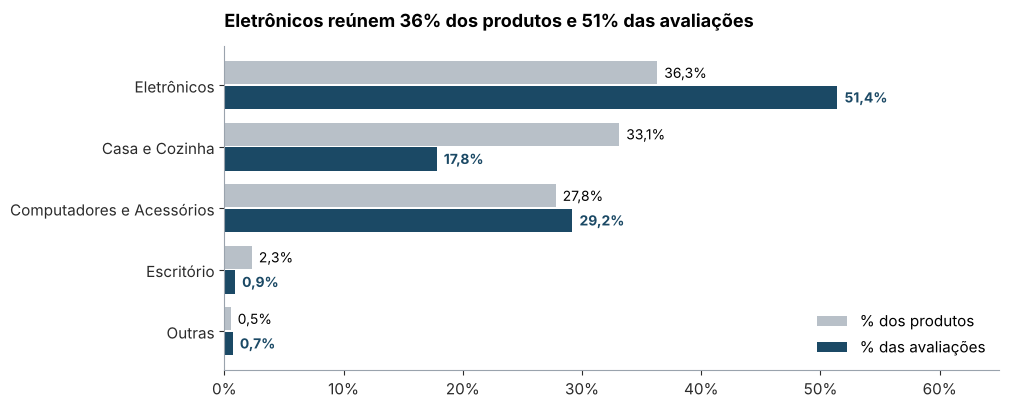

In [13]:
cats = por_categoria.index[::-1]
fig, ax = plt.subplots(figsize=(10, 4.2))
y = np.arange(len(cats))
ax.barh(y + 0.2, por_categoria.loc[cats, 'pct_produtos'], height=0.38, color=CINZA, label='% dos produtos')
ax.barh(y - 0.2, por_categoria.loc[cats, 'pct_avaliacoes'], height=0.38, color=AZUL, label='% das avaliações')
for i, c in enumerate(cats):
    ax.text(por_categoria.loc[c, 'pct_produtos'] + 0.6, i + 0.2, fmt_pct(por_categoria.loc[c, 'pct_produtos']),
            va='center', fontsize=10)
    ax.text(por_categoria.loc[c, 'pct_avaliacoes'] + 0.6, i - 0.2, fmt_pct(por_categoria.loc[c, 'pct_avaliacoes']),
            va='center', fontsize=10, color=AZUL, fontweight='bold')
ax.set_yticks(y, cats)
eixo_percentual(ax, 'x')
ax.set_xlim(0, 65)
ele = por_categoria.loc['Eletrônicos']
ax.set_title(f"Eletrônicos reúnem {fmt_pct(ele['pct_produtos'], 0)} dos produtos e {fmt_pct(ele['pct_avaliacoes'], 0)} das avaliações")
ax.legend(frameon=False, loc='lower right')
salvar(fig, '01_portfolio_categorias.png')

**Como ler este gráfico:** para cada categoria, a barra cinza mostra sua fatia do portfólio (quantidade de produtos) e a azul, sua fatia do engajamento (avaliações, contadas por família de variantes).

**Observações:**
- Eletrônicos atraem mais atenção do que o tamanho do sortimento sugere: 36% dos produtos e 51% das avaliações.
- Casa e Cozinha é o caso oposto: 33% dos produtos e só 18% das avaliações. É a categoria com mais espaço para ganhar visibilidade.
- Escritório é pequena, mas tem a melhor satisfação da base (tabela acima): nota média de 4,31 e todos os 31 produtos com nota ≥ 4,0. É também a categoria com o menor desconto médio (12%).

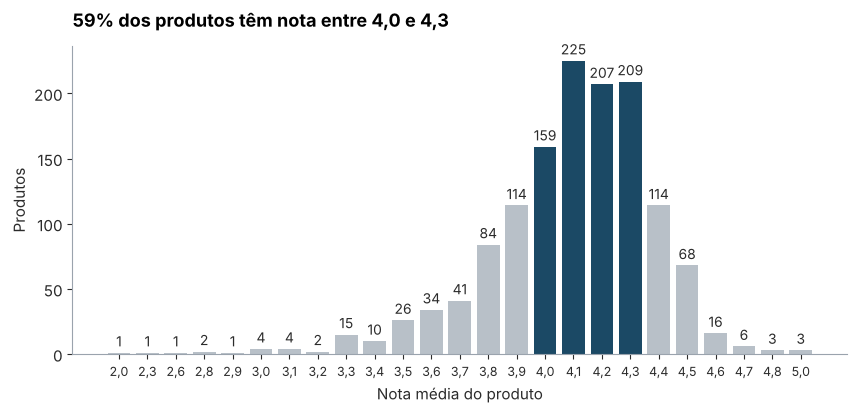

In [14]:
fig, ax = plt.subplots(figsize=(10, 4))
contagem = validos['rating'].round(1).value_counts().sort_index()
cores = [AZUL if 4.0 <= n <= 4.3 else CINZA for n in contagem.index]
ax.bar([fmt_num(n, 1) for n in contagem.index], contagem.values, color=cores)
rotular_barras(ax, contagem.values, lambda v: fmt_num(v))
ax.set_xlabel('Nota média do produto')
ax.set_ylabel('Produtos')
pct_faixa = validos['rating'].between(4.0, 4.3).mean() * 100
ax.set_title(f'{fmt_pct(pct_faixa, 0)} dos produtos têm nota entre 4,0 e 4,3')
plt.setp(ax.get_xticklabels(), fontsize=9)
salvar(fig, '02_distribuicao_notas.png')

**Observações:**
- A nota quase não varia: a média geral é 4,09 e só 3% dos produtos ficam abaixo de 3,5. Isso é típico de marketplace, porque produtos mal avaliados tendem a sair da vitrine.
- Por isso, diferenças pequenas na nota importam. Um produto com nota 3,7 já está entre os 10% piores da base.

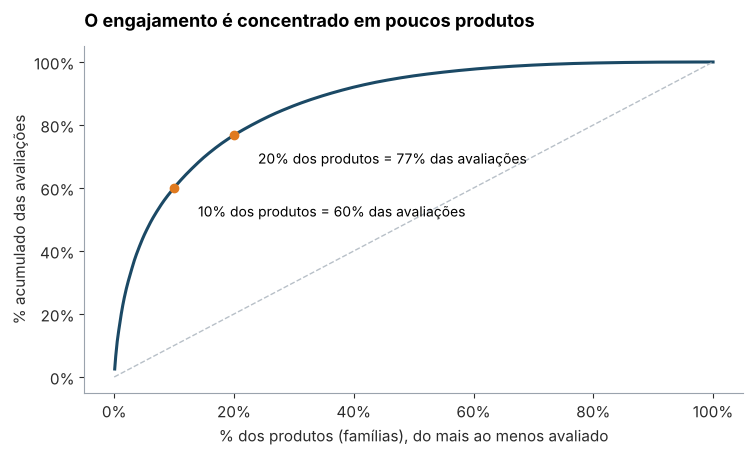

Top 10% das famílias: 60,0% das avaliações | Top 20%: 76,8%


In [15]:
aval_familia = familias['avaliacoes'].dropna().sort_values(ascending=False).reset_index(drop=True)
acumulado = aval_familia.cumsum() / aval_familia.sum() * 100
pct_familias = (np.arange(1, len(aval_familia) + 1)) / len(aval_familia) * 100
top10 = acumulado.iloc[int(len(aval_familia) * 0.10) - 1]
top20 = acumulado.iloc[int(len(aval_familia) * 0.20) - 1]

fig, ax = plt.subplots(figsize=(8.5, 4.5))
ax.plot(pct_familias, acumulado, color=AZUL, linewidth=2.2)
ax.plot([0, 100], [0, 100], color=CINZA, linestyle='--', linewidth=1)
for p, val in [(10, top10), (20, top20)]:
    ax.scatter(p, val, color=LARANJA, zorder=3)
    ax.annotate(f'{p}% dos produtos = {fmt_pct(val, 0)} das avaliações', (p, val), xytext=(p + 4, val - 9), fontsize=10)
ax.set_xlabel('% dos produtos (famílias), do mais ao menos avaliado')
ax.set_ylabel('% acumulado das avaliações')
eixo_percentual(ax, 'x')
eixo_percentual(ax)
ax.set_title('O engajamento é concentrado em poucos produtos')
salvar(fig, '03_concentracao_engajamento.png')
print(f'Top 10% das famílias: {fmt_pct(top10)} das avaliações | Top 20%: {fmt_pct(top20)}')

**Observações:**
- 10% dos produtos concentram cerca de 60% de todas as avaliações. A reputação da loja depende de poucos itens, o que torna esses produtos prioritários: um problema neles é visto por muito mais clientes.
- Se tivéssemos somado o `rating_count` sem agrupar as variantes, a concentração pareceria ainda maior, porque os campeões de engajamento são justamente os que têm várias versões.

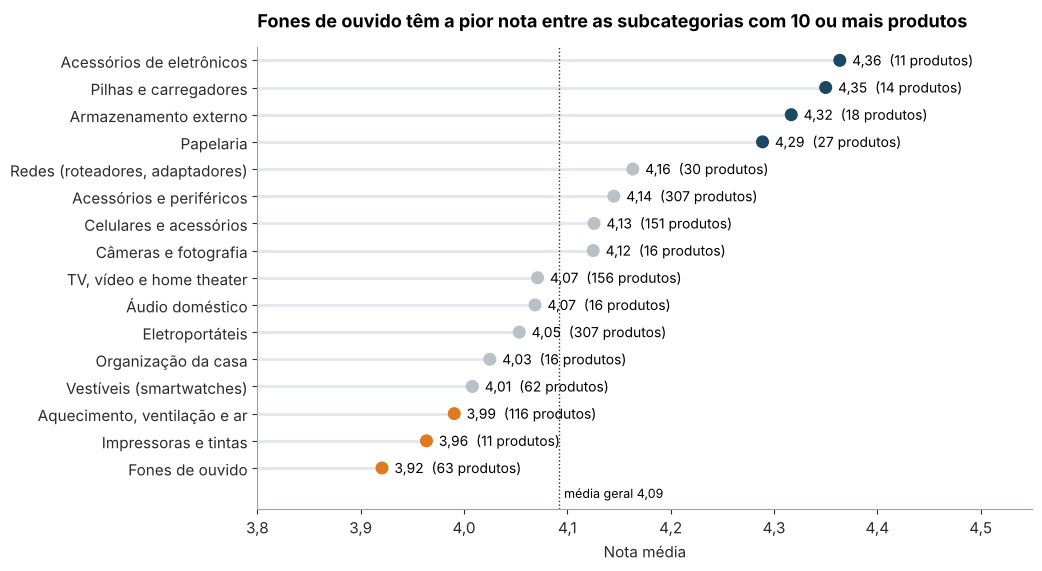

Categoria,Subcategoria,Produtos,Nota média,"% nota ≥ 4,0",Desconto médio (%)
Eletrônicos,Fones de ouvido,63,"3,92","47,62","59,49"
Computadores e Acessórios,Impressoras e tintas,11,"3,96","54,55","21,55"
Casa e Cozinha,"Aquecimento, ventilação e ar",116,"3,99","62,07","40,68"
Eletrônicos,Vestíveis (smartwatches),62,"4,01","70,97","69,71"
Casa e Cozinha,Organização da casa,16,"4,03","75,00","46,06"
Casa e Cozinha,Eletroportáteis,307,"4,05","69,06","40,34"
Eletrônicos,Áudio doméstico,16,"4,07","62,50","49,69"
Eletrônicos,"TV, vídeo e home theater",156,"4,07","71,79","49,39"
Eletrônicos,Câmeras e fotografia,16,"4,12","68,75","47,56"
Eletrônicos,Celulares e acessórios,151,"4,13","86,09","41,47"


In [16]:
sub = validos.groupby(['categoria', 'subcategoria']).agg(
    produtos=('product_id', 'size'),
    nota_media=('rating', 'mean'),
    pct_nota_4=('rating', lambda x: (x >= 4).mean() * 100),
    desconto_medio=('discount_percentage', 'mean'),
).reset_index()
sub = sub[sub['produtos'] >= 10].sort_values('nota_media')

fig, ax = plt.subplots(figsize=(10, 6))
cores = [LARANJA if n < 4.0 else (AZUL if n >= 4.25 else CINZA) for n in sub['nota_media']]
y = np.arange(len(sub))
# Pontos em vez de barras: o eixo começa em 3,8 e uma barra cortada exageraria as diferenças
ax.hlines(y, 3.8, sub['nota_media'], color='#E3E7EB', linewidth=2)
ax.scatter(sub['nota_media'], y, color=cores, s=70, zorder=3)
for i, (n, q) in enumerate(zip(sub['nota_media'], sub['produtos'])):
    ax.text(n + 0.012, i, f'{fmt_num(n, 2)}  ({q} produtos)', va='center', fontsize=10)
ax.set_yticks(y, sub['subcategoria'])
ax.set_xlim(3.8, 4.55)
ax.axvline(C, color=TEXTO, linestyle=':', linewidth=1)
ax.text(C + 0.005, -1.1, f'média geral {fmt_num(C, 2)}', fontsize=9)
ax.set_ylim(-1.5, len(sub) - 0.5)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: fmt_num(v, 1)))
ax.set_xlabel('Nota média')
ax.set_title('Fones de ouvido têm a pior nota entre as subcategorias com 10 ou mais produtos')
salvar(fig, '04_satisfacao_subcategorias.png')
exibir(sub, 2)

**Como ler este gráfico:** o eixo começa em 3,8 para deixar visíveis as diferenças, que são pequenas em valor absoluto (ver Seção 4.1). Por isso usamos pontos e não barras, que exagerariam as diferenças. Em laranja, subcategorias abaixo de 4,0; em azul, as de 4,25 ou mais.

**Observações:**
- Fones de ouvido (3,92) e impressoras e tintas (3,96) são as subcategorias com menor satisfação. Fones de ouvido também concentram muito engajamento e o maior desconto médio entre as grandes subcategorias (59%), uma combinação que vamos encontrar de novo nas Seções 5.2 e 5.3.
- Aquecimento, ventilação e ar (3,99) é a pior subcategoria de Casa e Cozinha.
- No topo estão subcategorias de compra simples e reposição: acessórios de eletrônicos, pilhas e carregadores, armazenamento externo e papelaria.

<a id="secao-5-2"></a>

### 5.2 Preços e descontos

Antes de cruzar desconto com satisfação, olhamos como a empresa usa o desconto: quanto se desconta, em quais categorias e em quais faixas de preço.

In [17]:
resumo_preco = validos.groupby('categoria').agg(
    preco_original_mediano=('actual_price', 'median'),
    preco_final_mediano=('discounted_price', 'median'),
    desconto_medio=('discount_percentage', 'mean'),
    pct_desconto_acima_60=('discount_percentage', lambda x: (x > 60).mean() * 100),
).sort_values('desconto_medio', ascending=False)
print(f"Desconto médio geral: {fmt_pct(validos['discount_percentage'].mean())} | mediana: {fmt_pct(validos['discount_percentage'].median(), 0)}")
print(f"Produtos com mais de 60% de desconto: {fmt_pct((validos['discount_percentage'] > 60).mean() * 100)}")
exibir(resumo_preco, 1)

Desconto médio geral: 46,7% | mediana: 49%
Produtos com mais de 60% de desconto: 27,9%


,Preço original mediano (₹),Preço final mediano (₹),Desconto médio (%),% com desconto acima de 60%
Categoria,,,,
Computadores e Acessórios,999,399,"53,2","41,1"
Eletrônicos,2.999,1.384,"49,9","35,7"
Outras,999,478,"43,1","0,0"
Casa e Cozinha,2.000,1.199,"40,2","10,5"
Escritório,210,178,"12,4","3,2"


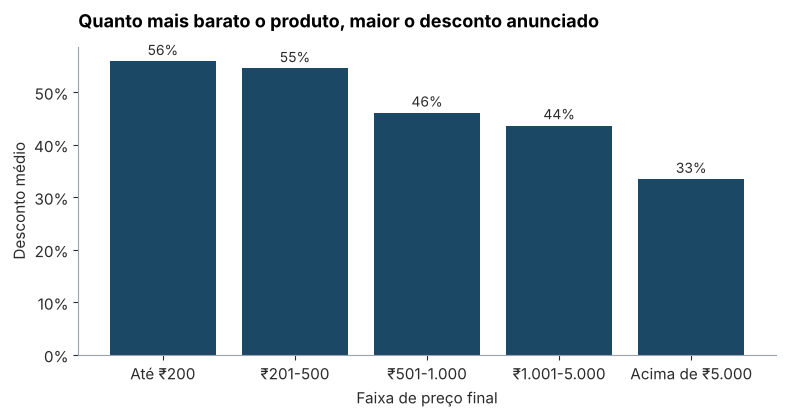

,Produtos,Desconto médio (%),Nota média,Avaliações por produto (mediana)
Faixa de preço,,,,
Até ₹200,160,"55,85","4,04",3.095
₹201-500,341,"54,50","4,08",2.685
₹501-1.000,237,"46,04","4,11",6.183
₹1.001-5.000,409,"43,62","4,07",7.148
Acima de ₹5.000,203,"33,41","4,17",6.753


In [18]:
por_faixa_preco = validos.groupby('faixa_preco', observed=True).agg(
    produtos=('product_id', 'size'),
    desconto_medio=('discount_percentage', 'mean'),
    nota_media=('rating', 'mean'),
    avaliacoes_medianas=('rating_count', 'median'),
)

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(por_faixa_preco.index.astype(str), por_faixa_preco['desconto_medio'], color=AZUL)
rotular_barras(ax, por_faixa_preco['desconto_medio'], lambda v: fmt_pct(v, 0))
eixo_percentual(ax)
ax.set_ylabel('Desconto médio')
ax.set_xlabel('Faixa de preço final')
ax.set_title('Quanto mais barato o produto, maior o desconto anunciado')
salvar(fig, '05_desconto_por_faixa_preco.png')
exibir(por_faixa_preco, 2)

**Observações:**
- O desconto é a regra, não a exceção: a mediana é de 49% e quase três em cada dez produtos (28%) são anunciados com mais de 60% de desconto.
- Produtos baratos têm os maiores descontos (56% até ₹200 contra 33% acima de ₹5.000). Em itens de baixo valor, um preço "original" alto com desconto grande parece funcionar mais como argumento de vitrine do que como redução real de preço.
- Computadores e Acessórios é a categoria que mais desconta (53% em média) e Escritório a que menos desconta (12%).

#### Desconto maior traz mais satisfação ou mais engajamento?

Essa é a pergunta que mais interessa à liderança na cadeia Preço → Desconto → Engajamento → Satisfação. Medimos a relação de duas formas: por faixa de desconto e pela correlação de Spearman, que é a mais adequada aqui porque nota e engajamento não têm distribuição normal.

In [19]:
por_faixa_desc = validos.groupby('faixa_desconto', observed=True).agg(
    produtos=('product_id', 'size'),
    nota_media=('rating', 'mean'),
    pct_nota_4=('rating', lambda x: (x >= 4).mean() * 100),
    pct_abaixo_38=('rating', lambda x: (x < 3.8).mean() * 100),
    avaliacoes_medianas=('rating_count', 'median'),
)

for nome, col in [('nota', 'rating'), ('engajamento', 'rating_count')]:
    r = stats.spearmanr(validos['discount_percentage'], validos[col], nan_policy='omit')
    print(f'Desconto x {nome}: Spearman = {fmt_num(r.statistic, 2)} (p-valor = {r.pvalue:.1e})')
exibir(por_faixa_desc, 2)

Desconto x nota: Spearman = -0,15 (p-valor = 3.3e-08)
Desconto x engajamento: Spearman = -0,13 (p-valor = 1.1e-06)


,Produtos,Nota média,"% nota ≥ 4,0","% nota abaixo de 3,8",Avaliações por produto (mediana)
Faixa de desconto,,,,,
0-20%,175,"4,17","83,43","5,14",6.736
21-40%,329,"4,13","80,24","6,38",7.241
41-60%,469,"4,07","71,64","11,94",3.025
61-80%,326,"4,07","72,09","14,42",4.147
81-94%,51,"3,97","56,86","17,65",4.426


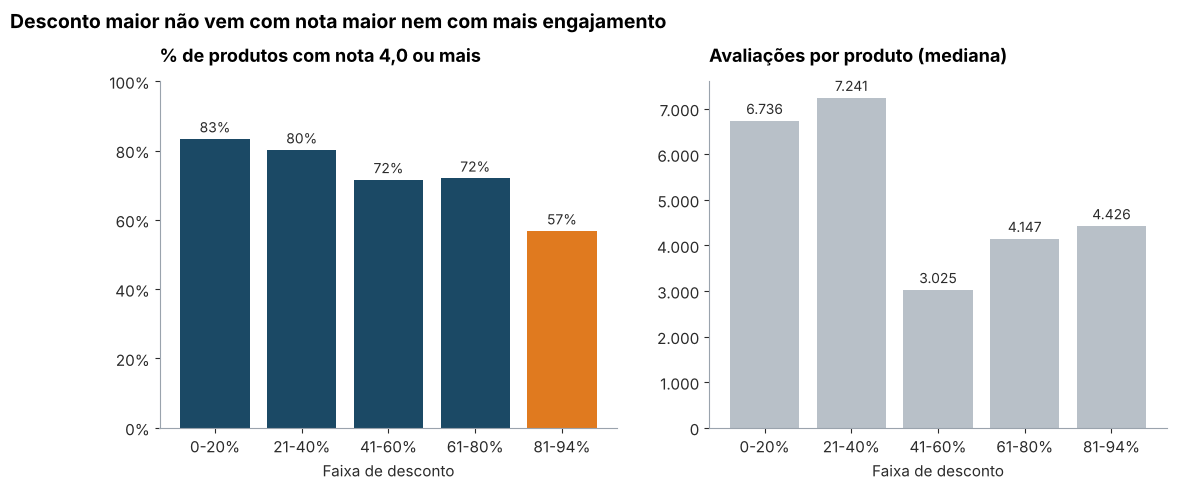

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
x = por_faixa_desc.index.astype(str)

ax = axes[0]
ax.bar(x, por_faixa_desc['pct_nota_4'], color=[AZUL] * 4 + [LARANJA])
rotular_barras(ax, por_faixa_desc['pct_nota_4'], lambda v: fmt_pct(v, 0))
ax.set_ylim(0, 100)
eixo_percentual(ax)
ax.set_xlabel('Faixa de desconto')
ax.set_title('% de produtos com nota 4,0 ou mais')

ax = axes[1]
ax.bar(x, por_faixa_desc['avaliacoes_medianas'], color=CINZA)
rotular_barras(ax, por_faixa_desc['avaliacoes_medianas'], lambda v: fmt_num(v))
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: fmt_num(v)))
ax.set_xlabel('Faixa de desconto')
ax.set_title('Avaliações por produto (mediana)')

fig.suptitle('Desconto maior não vem com nota maior nem com mais engajamento', x=0.01, ha='left',
             fontsize=14, fontweight='bold', y=1.04)
salvar(fig, '06_desconto_nota_engajamento.png')

**Como ler este gráfico:** à esquerda, a proporção de produtos bem avaliados em cada faixa de desconto; à direita, quantas avaliações um produto típico de cada faixa recebe.

**Observações:**
- **A proporção de produtos bem avaliados cai à medida que o desconto sobe:** 83% dos produtos com até 20% de desconto têm nota ≥ 4,0, contra 57% dos que têm mais de 80%. Na outra ponta, os produtos com nota abaixo de 3,8 vão de 5% para 18%.
- O desconto também não compra engajamento. Produtos com até 40% de desconto têm mais que o dobro de avaliações (mediana acima de 6,7 mil) do que os da faixa de 41% a 60% (cerca de 3 mil).
- As correlações confirmam a direção, mas são fracas (−0,15 com a nota e −0,13 com o engajamento). O desconto não *causa* nota baixa. O que os dados mostram é que descontos agressivos estão associados a produtos de percepção pior. Uma hipótese é que esses descontos sejam usados para empurrar produtos que já vendem e avaliam mal.
- Na Seção 6.5 voltamos a essa pergunta pelos comentários, que ajudam a entender *por que* isso acontece.

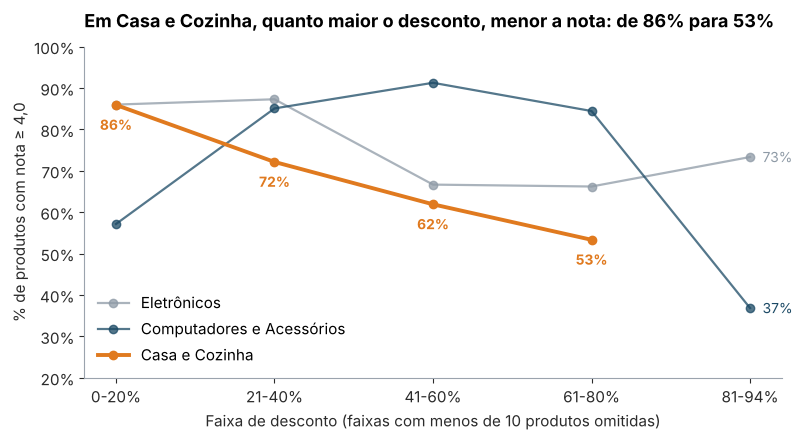

Eletrônicos: Spearman desconto x nota = -0,16
Computadores e Acessórios: Spearman desconto x nota = -0,19
Casa e Cozinha: Spearman desconto x nota = -0,22


In [21]:
principais = ['Eletrônicos', 'Computadores e Acessórios', 'Casa e Cozinha']
grupo = validos[validos['categoria'].isin(principais)].groupby(['categoria', 'faixa_desconto'], observed=True)['rating']
dentro = grupo.apply(lambda x: (x >= 4).mean() * 100).unstack(0)
qtd = grupo.size().unstack(0)
dentro_valido = dentro.where(qtd >= 10)   # faixas com menos de 10 produtos ficam fora do gráfico

fig, ax = plt.subplots(figsize=(9, 4.3))
for cat, cor in zip(principais, ['#8E9AA6', AZUL, LARANJA]):
    s = dentro_valido[cat].dropna()
    destaque = cat == 'Casa e Cozinha'
    ax.plot(s.index.astype(str), s.values, marker='o', color=cor, linewidth=2.8 if destaque else 1.6,
            alpha=1 if destaque else 0.75, label=cat, zorder=3 if destaque else 2)
    # Só a série em destaque leva rótulo em todos os pontos; as outras, só no último, para não embaralhar
    pontos = list(zip(s.index.astype(str), s.values)) if destaque else [(str(s.index[-1]), s.values[-1])]
    for xi, v in pontos:
        if destaque:
            ax.text(xi, v - 6, fmt_pct(v, 0), ha='center', color=cor, fontsize=10, fontweight='bold')
        else:
            ax.annotate(fmt_pct(v, 0), (xi, v), xytext=(9, 0), textcoords='offset points',
                        ha='left', va='center', color=cor, fontsize=10)
ax.set_ylim(20, 100)
eixo_percentual(ax)
ax.set_xlabel('Faixa de desconto (faixas com menos de 10 produtos omitidas)')
ax.set_ylabel('% de produtos com nota ≥ 4,0')
cc = dentro_valido['Casa e Cozinha'].dropna()
ax.set_title(f'Em Casa e Cozinha, quanto maior o desconto, menor a nota: de {fmt_pct(cc.iloc[0], 0)} para {fmt_pct(cc.iloc[-1], 0)}')
ax.legend(frameon=False, loc='lower left')
salvar(fig, '07_desconto_nota_por_categoria.png')
for cat in principais:
    s = validos[validos['categoria'] == cat]
    print(f"{cat}: Spearman desconto x nota = {fmt_num(stats.spearmanr(s['discount_percentage'], s['rating']).statistic, 2)}")
exibir(pd.concat({'% nota ≥ 4,0': dentro, 'Produtos': qtd}, axis=1), 1)

**Observações:**
- Verificamos se o padrão não era só efeito de mistura de categorias (por exemplo, categorias com muito desconto que já teriam nota pior). Não é: dentro das três categorias principais a correlação continua negativa (de −0,16 a −0,22). O formato da queda, porém, muda:
    - Casa e Cozinha tem a queda mais clara e contínua: de 86% de produtos bem avaliados na faixa de até 20% para 53% na de 61% a 80%. É a categoria em que desconto agressivo mais sinaliza problema.
    - Eletrônicos cai de 86-87% para 66-67% a partir de 41% de desconto.
    - Computadores e Acessórios mantém a nota até 80% de desconto e só cai acima disso (37%). A faixa de pouco desconto também tem nota menor (57%), puxada por impressoras e tintas, que quase não têm desconto e são mal avaliadas.
- Uma faixa de Casa e Cozinha (acima de 80%) tem só 2 produtos e ficou fora do gráfico, para não mostrar um percentual sem base.

#### E se for o preço, e não o desconto?

Produtos baratos têm desconto maior. Então a nota menor poderia vir do produto ser barato, e não do desconto. Testamos isso de duas formas: comparando desconto baixo e alto dentro de cada faixa de preço, e com uma regressão logística que estima o efeito do desconto mantendo preço e categoria constantes.

In [22]:
r_preco = stats.spearmanr(validos['discount_percentage'], validos['discounted_price'])
print(f"Desconto x preço: Spearman = {fmt_num(r_preco.statistic, 2)}")

comparacao = []
for faixa, g in validos.groupby('faixa_preco', observed=True):
    baixo = g[g['discount_percentage'] <= 40]
    alto = g[g['discount_percentage'] > 60]
    comparacao.append({'faixa_preco': faixa,
                       'produtos (desconto até 40%)': len(baixo),
                       '% nota ≥ 4,0 (desconto até 40%)': (baixo['rating'] >= 4).mean() * 100,
                       'produtos (desconto acima de 60%)': len(alto),
                       '% nota ≥ 4,0 (desconto acima de 60%)': (alto['rating'] >= 4).mean() * 100})
comparacao = pd.DataFrame(comparacao).set_index('faixa_preco')
exibir(comparacao, 1)

Desconto x preço: Spearman = -0,37


,produtos (desconto até 40%),"% nota ≥ 4,0 (desconto até 40%)",produtos (desconto acima de 60%),"% nota ≥ 4,0 (desconto acima de 60%)"
Faixa de preço,,,,
Até ₹200,36,"86,1",83,"62,7"
₹201-500,68,"70,6",160,"73,1"
₹501-1.000,78,"82,1",44,"70,5"
₹1.001-5.000,180,"76,7",82,"69,5"
Acima de ₹5.000,142,"90,8",8,"87,5"


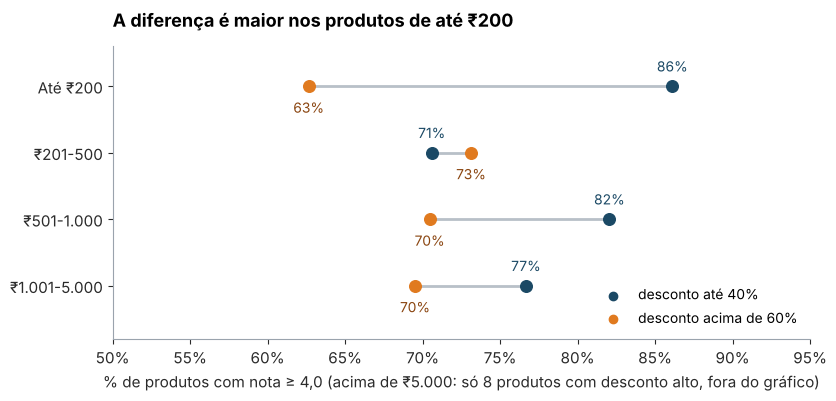

In [23]:
# Faixas com menos de 10 produtos em algum dos grupos ficam fora do gráfico
comp = comparacao[(comparacao['produtos (desconto até 40%)'] >= 10) & (comparacao['produtos (desconto acima de 60%)'] >= 10)]

fig, ax = plt.subplots(figsize=(9, 3.8))
y = np.arange(len(comp))[::-1]
for yi, (faixa, row) in zip(y, comp.iterrows()):
    a, b = row['% nota ≥ 4,0 (desconto até 40%)'], row['% nota ≥ 4,0 (desconto acima de 60%)']
    ax.plot([a, b], [yi, yi], color=CINZA, linewidth=2, zorder=1)
    ax.scatter(a, yi, color=AZUL, s=70, zorder=2)
    ax.scatter(b, yi, color=LARANJA, s=70, zorder=2)
    ax.text(a, yi + 0.22, fmt_pct(a, 0), ha='center', fontsize=10, color=AZUL)
    ax.text(b, yi - 0.4, fmt_pct(b, 0), ha='center', fontsize=10, color='#8A4510')
ax.set_yticks(y, comp.index.astype(str))
ax.set_xlim(50, 95)
ax.set_ylim(-0.8, len(comp) - 0.4)
eixo_percentual(ax, 'x')
ax.set_xlabel('% de produtos com nota ≥ 4,0 (acima de ₹5.000: só 8 produtos com desconto alto, fora do gráfico)')
ax.scatter([], [], color=AZUL, label='desconto até 40%')
ax.scatter([], [], color=LARANJA, label='desconto acima de 60%')
ax.legend(frameon=False, loc='lower right', fontsize=10)
ax.set_title('A diferença é maior nos produtos de até ₹200')
salvar(fig, '13_desconto_nota_por_faixa_preco.png')

In [24]:
# Escritório fica fora: todos os produtos têm nota >= 4,0, o que impede a estimativa (separação perfeita).
# Outras fica fora por ter só 7 produtos.
modelo_base = validos[validos['categoria'].isin(['Eletrônicos', 'Casa e Cozinha', 'Computadores e Acessórios'])].copy()
modelo_base['bem_avaliado'] = (modelo_base['rating'] >= 4).astype(int)
modelo_base['desconto_10pp'] = modelo_base['discount_percentage'] / 10
modelo_base['log_preco'] = np.log10(modelo_base['discounted_price'])

modelos = {
    'Só desconto': 'bem_avaliado ~ desconto_10pp',
    'Desconto + categoria': 'bem_avaliado ~ desconto_10pp + categoria',
    'Desconto + preço + categoria': 'bem_avaliado ~ desconto_10pp + log_preco + categoria',
}
linhas = []
for nome, formula in modelos.items():
    m = smf.logit(formula, data=modelo_base).fit(disp=0)
    ic = np.exp(m.conf_int().loc['desconto_10pp'])
    linhas.append({'modelo': nome,
                   'Razão de chances (+10 p.p. de desconto)': np.exp(m.params['desconto_10pp']),
                   'IC 95% inferior': ic.iloc[0], 'IC 95% superior': ic.iloc[1],
                   'p-valor': '< 0,001' if m.pvalues['desconto_10pp'] < 0.001 else fmt_num(m.pvalues['desconto_10pp'], 3)})

m_inter = smf.logit('bem_avaliado ~ desconto_10pp * log_preco + categoria', data=modelo_base).fit(disp=0)
print(f"Produtos no modelo: {len(modelo_base)}")
print(f"Interação desconto x preço: p-valor = {fmt_num(m_inter.pvalues['desconto_10pp:log_preco'], 2)}")
exibir(pd.DataFrame(linhas).set_index('modelo'), 2)

Produtos no modelo: 1312
Interação desconto x preço: p-valor = 0,70


,Razão de chances (+10 p.p. de desconto),IC 95% inferior,IC 95% superior,p-valor
Modelo,,,,
Só desconto,"0,87","0,82","0,92","< 0,001"
Desconto + categoria,"0,82","0,77","0,88","< 0,001"
Desconto + preço + categoria,"0,87","0,82","0,94","< 0,001"


**Como ler:** a razão de chances mostra quanto muda a chance de um produto ter nota 4,0 ou mais a cada 10 pontos percentuais a mais de desconto. Abaixo de 1, a chance cai; 0,87 quer dizer uma queda de 13%.

**Observações:**
- O efeito do desconto continua depois de controlar preço e categoria. A cada 10 pontos a mais de desconto, a chance de o produto ter nota 4,0 ou mais cai cerca de 13% (razão de chances de 0,87, intervalo de confiança de 0,81 a 0,94). Parte da relação vinha mesmo do preço: controlando só a categoria, a queda estimada era de 18%. Mas a maior parte se mantém.
- A diferença é mais forte nos produtos baratos. Até ₹200, 86% dos produtos com até 40% de desconto são bem avaliados, contra 63% dos que têm mais de 60%. Entre ₹501 e ₹5.000 a diferença existe, mas é menor (de 7 a 12 pontos), e entre ₹201 e ₹500 ela não aparece. Acima de ₹5.000 quase não há produtos com desconto alto.
- A regressão não confirma estatisticamente que o efeito muda com o preço (p-valor de 0,7 para a interação). Por isso tratamos a concentração nos produtos baratos como indício, não como conclusão.
- Isso muda a recomendação: a revisão da política de descontos deve começar pelos itens baratos com desconto acima de 60%, a maioria cabos e acessórios de Computadores e Acessórios.

<a id="secao-5-3"></a>

### 5.3 Engajamento × satisfação

Cruzamos as duas dimensões para classificar o portfólio em quatro grupos. Os cortes são:
- **Engajamento alto:** `rating_count` acima da mediana da base (4.740 avaliações);
- **Satisfação alta:** nota ≥ 4,0, o mesmo corte do indicador "% de produtos com nota ≥ 4,0".

In [25]:
corte_eng = validos['rating_count'].median()
eng_alto = validos['rating_count'] >= corte_eng
nota_alta = validos['rating'] >= 4.0

validos['quadrante'] = np.select(
    [eng_alto & nota_alta, eng_alto & ~nota_alta, ~eng_alto & nota_alta],
    ['Consolidados', 'Atenção: alcance alto, nota baixa', 'Oportunidade: nota alta, pouca visibilidade'],
    default='Baixa prioridade')
validos.loc[validos['rating_count'].isna(), 'quadrante'] = 'Sem dados de engajamento'
df['quadrante'] = validos['quadrante']

r = stats.spearmanr(validos['rating_count'], validos['rating'], nan_policy='omit')
print(f'Corte de engajamento (mediana): {fmt_num(corte_eng)} avaliações')
print(f'Engajamento x nota: Spearman = {fmt_num(r.statistic, 2)} (p-valor = {r.pvalue:.1e})')
exibir(validos['quadrante'].value_counts().to_frame('produtos').assign(
    pct=lambda x: x['produtos'] / x['produtos'].sum() * 100))

Corte de engajamento (mediana): 4.740 avaliações
Engajamento x nota: Spearman = 0,19 (p-valor = 8.3e-13)


,Produtos,% dos produtos
Grupo,,
Consolidados,563,"41,7"
"Oportunidade: nota alta, pouca visibilidade",446,"33,0"
Baixa prioridade,227,"16,8"
"Atenção: alcance alto, nota baixa",112,"8,3"
Sem dados de engajamento,2,"0,1"


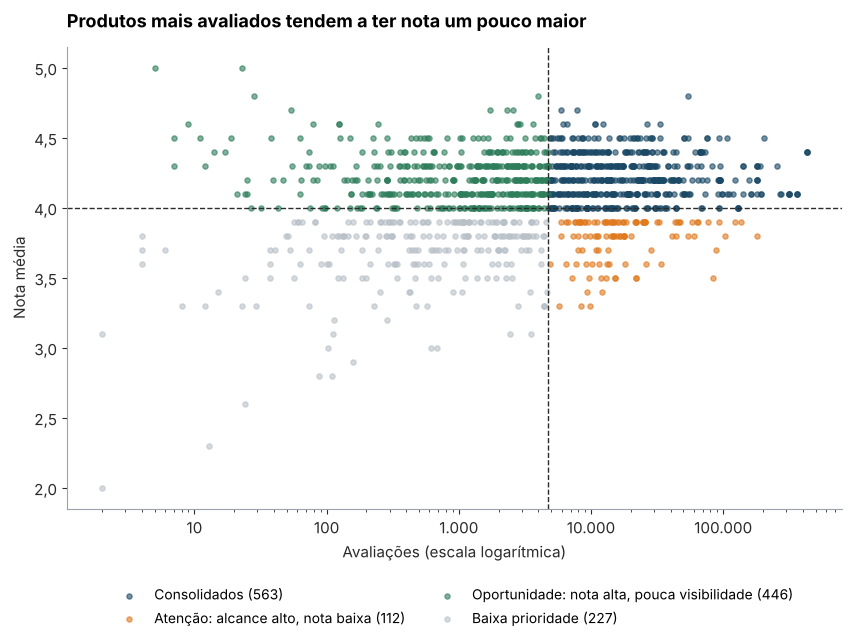

In [26]:
cores_quad = {'Consolidados': AZUL, 'Atenção: alcance alto, nota baixa': LARANJA,
              'Oportunidade: nota alta, pouca visibilidade': VERDE, 'Baixa prioridade': CINZA}
fig, ax = plt.subplots(figsize=(10, 6))
for q, cor in cores_quad.items():
    s = validos[validos['quadrante'] == q]
    ax.scatter(s['rating_count'], s['rating'], s=14, alpha=0.6, color=cor, label=f'{q} ({len(s)})')
ax.set_xscale('log')
ax.axvline(corte_eng, color=TEXTO, linestyle='--', linewidth=1)
ax.axhline(4.0, color=TEXTO, linestyle='--', linewidth=1)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: fmt_num(v)))
ax.set_xlabel('Avaliações (escala logarítmica)')
ax.set_ylabel('Nota média')
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: fmt_num(v, 1)))
ax.set_title('Produtos mais avaliados tendem a ter nota um pouco maior')
ax.legend(frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.14), ncol=2, fontsize=10)
salvar(fig, '08_quadrantes_engajamento_satisfacao.png')

**Como ler este gráfico:** cada ponto é um produto. As linhas tracejadas são os cortes (mediana de avaliações e nota 4,0) e dividem o portfólio em quatro grupos.

**Observações:**
- A relação entre engajamento e nota é positiva e fraca (0,19): produtos mais avaliados tendem a ter nota um pouco maior. Faz sentido, porque um produto bom acumula avaliações por mais tempo e com mais vendas.
- Ainda assim, há produtos importantes fora desse padrão, que são os dois grupos que respondem diretamente às perguntas do desafio. Listamos os principais abaixo, usando cortes mais rígidos para separar os casos mais claros.

#### Alto engajamento e baixa avaliação: risco de reputação

Selecionamos os produtos entre os 25% mais avaliados e com nota abaixo de 4,0. Mostramos uma linha por família de variantes, para o mesmo anúncio não aparecer repetido.

In [27]:
p75 = validos['rating_count'].quantile(0.75)
risco = (validos[(validos['rating_count'] >= p75) & (validos['rating'] < 4.0)]
         .sort_values('rating_count', ascending=False)
         .drop_duplicates('familia_id'))
print(f'Corte: {fmt_num(p75)} avaliações (75º percentil)')
print(f'Produtos no grupo: {len(risco)} famílias')
print('Por subcategoria:', risco['subcategoria'].value_counts().head(4).to_dict())
exibir(risco[['nome_curto', 'subcategoria', 'rating', 'rating_count', 'discount_percentage']].head(10))

Corte: 16.052 avaliações (75º percentil)
Produtos no grupo: 40 famílias
Por subcategoria: {'Fones de ouvido': 14, 'Eletroportáteis': 12, 'Celulares e acessórios': 3, 'Acessórios e periféricos': 3}


Produto,Subcategoria,Nota,Avaliações,Desconto (%)
boAt Airdopes 121v2 in-Ear True Wireless Earbuds with Upto 1,Fones de ouvido,"3,8",180.998,57
boAt Airdopes 141 Bluetooth Truly Wireless in Ear Earbuds wi,Fones de ouvido,"3,9",136.954,67
Pigeon by Stovekraft Amaze Plus Electric Kettle,Eletroportáteis,"3,9",123.365,48
Boult Audio Probass Curve Bluetooth Wireless in Ear Earphone,Fones de ouvido,"3,8",103.052,80
JBL C50HI,Fones de ouvido,"3,9",92.995,50
JBL Tune 215BT,Fones de ouvido,"3,7",87.798,50
PTron Tangent Lite Bluetooth 5.0 Earphones with Mic,Fones de ouvido,"3,5",83.996,67
Boult Audio BassBuds X1 in-Ear Wired Earphones with 10mm Ext,Fones de ouvido,"3,9",77.027,67
Zebronics ZEB-COUNTY 3W Wireless Bluetooth Portable Speaker,Áudio doméstico,"3,9",64.705,45
Prestige Electric Kettle PKOSS - 1500watts,Eletroportáteis,"3,9",63.350,48


**Observações:**
- São 40 famílias de produtos muito avaliados com nota abaixo de 4,0. Os maiores grupos são fones de ouvido (14) e eletroportáteis (12), como chaleiras elétricas.
- Esses produtos são o maior risco de reputação da loja: estão entre os mais vistos e comprados e deixam uma parte relevante dos clientes insatisfeita.
- O desconto mediano desse grupo é de 54%, acima da média da base (47%). É mais um sinal da relação entre desconto alto e nota baixa que vimos na Seção 5.2.

#### Boa avaliação e pouca visibilidade: oportunidade

Aqui o cuidado é outro: produtos com 5 avaliações e nota 5,0 não são confiáveis. Exigimos **ao menos 100 avaliações** e consideramos os produtos abaixo do 25º percentil de engajamento com nota ≥ 4,3.

In [28]:
p25 = validos['rating_count'].quantile(0.25)
joias = (validos[(validos['rating_count'].between(100, p25)) & (validos['rating'] >= 4.3)]
         .sort_values('nota_ponderada', ascending=False)
         .drop_duplicates('familia_id'))
print(f'Corte: entre 100 e {fmt_num(p25)} avaliações (25º percentil) e nota ≥ 4,3')
print(f'Produtos no grupo (uma linha por família de variantes): {len(joias)}')
print('Por categoria:', joias['categoria'].value_counts().to_dict())
exibir(joias[['nome_curto', 'subcategoria', 'rating', 'rating_count', 'discount_percentage']].head(10))

Corte: entre 100 e 1.108 avaliações (25º percentil) e nota ≥ 4,3
Produtos no grupo (uma linha por família de variantes): 58
Por categoria: {'Casa e Cozinha': 21, 'Eletrônicos': 21, 'Computadores e Acessórios': 15, 'Escritório': 1}


Produto,Subcategoria,Nota,Avaliações,Desconto (%)
Cafe JEI French Press Coffee and Tea Maker 600ml with 4 Leve,Eletroportáteis,"4,5",1.065,27
AmazonBasics 10.2 Gbps High-Speed 4K HDMI Cable with Braided,"TV, vídeo e home theater","4,5",1.029,59
Duracell USB Lightning Apple Certified,Acessórios e periféricos,"4,5",815,46
INOVERA World Map Extended Anti Slip Rubber Gaming Stitched,Acessórios e periféricos,"4,4",1.030,50
Kyosei Advanced Tempered Glass Compatible with Google Pixel,Celulares e acessórios,"4,5",596,75
Belkin USB C to USB-C Fast Charging Type C Cable,Acessórios e periféricos,"4,5",577,29
InstaCuppa Portable Blender for Smoothie,Eletroportáteis,"4,5",546,20
Cotbolt Silicone Protective Case Cover for LG an MR21GA Magi,"TV, vídeo e home theater","4,5",505,80
"Fire-Boltt Tank 1.85"" Bluetooth Calling Smart Watch",Vestíveis (smartwatches),"4,4",768,75
Belkin USB C to USB-C Fast Charging Type C Cable,Acessórios e periféricos,"4,5",474,29


**Observações:**
- Encontramos 58 produtos bem avaliados e pouco vistos, espalhados pelas três categorias principais (21 em Casa e Cozinha, 21 em Eletrônicos e 15 em Computadores e Acessórios).
- São candidatos naturais a ganhar exposição (destaque na busca, recomendação, campanhas), porque a qualidade já foi comprovada por quem comprou. Para Casa e Cozinha, que tem pouca visibilidade como categoria (Seção 5.1), essa lista é um bom ponto de partida.

<a id="secao-6"></a>

## 6. Customer Insights: o que prometem as descrições e o que dizem as avaliações

A nota média responde *quanto* o cliente gostou. Os comentários respondem *por quê*. Nesta seção procuramos responder às quatro perguntas do desafio:

1. O que os clientes mais valorizam?
2. Quais problemas aparecem com maior frequência?
3. Quais padrões estão presentes em avaliações positivas?
4. Quais temas aparecem em avaliações negativas?

Depois, mostramos como os comentários complementam os indicadores: o que eles revelam que a nota média esconde.

<a id="secao-6-1"></a>

### 6.1 Separando as avaliações

A base guarda até 8 avaliações por produto na mesma célula, separadas por vírgula. O problema é que os próprios textos também têm vírgulas. Testamos alguns padrões de separação e verificamos, família a família, se o número de textos separados bate com o número de `review_id`:

In [29]:
fam = df.drop_duplicates('familia_id').copy()   # cada família de variantes entra uma vez
qtd_ids = fam['review_id'].str.split(',').str.len()

padroes = {
    'qualquer vírgula': r',',
    'vírgula seguida de maiúscula': r',(?=[A-Z])',
    'vírgula sem espaço depois': r',(?=\S)',
}
teste = pd.DataFrame({
    nome: {col: ((fam[col].str.split(p).str.len() == qtd_ids).mean() * 100)
           for col in ['review_title', 'review_content']}
    for nome, p in padroes.items()
}).T.round(1)
teste.columns = ['% de famílias com títulos alinhados', '% de famílias com textos alinhados']
exibir(teste)

,% de famílias com títulos alinhados,% de famílias com textos alinhados
qualquer vírgula,"67,3","13,3"
vírgula seguida de maiúscula,"66,2","43,4"
vírgula sem espaço depois,"95,7","74,8"


O padrão **"vírgula sem espaço depois"** funciona porque, ao juntar as avaliações, a base não deixou espaço entre elas, enquanto no texto escrito pelo cliente a vírgula costuma vir seguida de espaço. Ele alinha 96% dos títulos e 75% dos textos.

**Decisão:** usamos apenas as famílias em que títulos **e** textos ficaram perfeitamente alinhados com os IDs. Preferimos perder cerca de um quarto da amostra a analisar textos cortados ao meio. Antes de seguir, conferimos se essa amostra continua representando a base:

In [30]:
SEP = r',(?=\S)'
ids = fam['review_id'].str.split(',')
titulos = fam['review_title'].str.split(SEP)
textos = fam['review_content'].str.split(SEP)
alinhada = (titulos.str.len() == ids.str.len()) & (textos.str.len() == ids.str.len())

representatividade = pd.DataFrame({
    'Todas as famílias': [len(fam), fam['rating'].mean()] + list(fam['categoria'].value_counts(normalize=True).mul(100).head(3)),
    'Famílias usadas': [alinhada.sum(), fam.loc[alinhada, 'rating'].mean()] +
                       list(fam.loc[alinhada, 'categoria'].value_counts(normalize=True).mul(100).reindex(
                           fam['categoria'].value_counts().index[:3])),
}, index=['Famílias', 'Nota média'] + [f'% {c}' for c in fam['categoria'].value_counts().index[:3]])
formato_linha = {'Famílias': lambda v: fmt_num(v), 'Nota média': lambda v: fmt_num(v, 2)}
representatividade.apply(lambda linha: linha.map(formato_linha.get(linha.name, fmt_pct)), axis=1)

,Todas as famílias,Famílias usadas
Famílias,1.188,860
Nota média,"4,08","4,09"
% Casa e Cozinha,"37,7%","36,9%"
% Eletrônicos,"32,2%","32,1%"
% Computadores e Acessórios,"26,9%","28,0%"


In [31]:
linhas = []
for (_, prod), tit, txt, rid in zip(fam[alinhada].iterrows(), titulos[alinhada], textos[alinhada], ids[alinhada]):
    for t, c, i in zip(tit, txt, rid):
        linhas.append({'review_id': i, 'product_id': prod['product_id'], 'familia_id': prod['familia_id'],
                       'categoria': prod['categoria'], 'subcategoria': prod['subcategoria'],
                       'rating': prod['rating'], 'discount_percentage': prod['discount_percentage'],
                       'faixa_desconto': prod['faixa_desconto'], 'titulo': t.strip(), 'texto': c.strip()})
reviews = pd.DataFrame(linhas).drop_duplicates('review_id').reset_index(drop=True)
print(f'Avaliações individuais: {fmt_num(len(reviews))} | famílias: {reviews["familia_id"].nunique()} '
      f'| palavras por avaliação (mediana): {reviews["texto"].str.split().str.len().median():.0f}')
exibir(reviews[['titulo', 'texto']].head(5))

Avaliações individuais: 6.718 | famílias: 858 | palavras por avaliação (mediana): 9


Título,Texto
Best value for money,"The sound quality of this earphone are really good. The bass part was also good. I only found the noise cancellation was not what I expected. It could be much better. Finally, I can say its a good value for money."
HEAD PHONE POUCH NOT RECEIVED,"At this purchase, i did'nt received head phone pouch to keep my head phones safe... it disappointed me"
Overall good in this pricerange,"overall good and decent quality, I am writing this after two months, I dont use regularly but whenever I use my colleagues says that your voice is clear 😂"
"It's not working in my Phone properly Plz help me in exchange or return, I ll be thankful to you",Pin that I do connect to the phone gets automatically to outside. It doesn't work. Plz amazon help me. I'm a regular customer of this company. I'll be really thankful to you.
Worth the money 🤑,Great sound quality and good bass. Decent noise cancellation. I couldn't have asked for better earphones at this price.


**Observações:**
- Ficamos com 6.718 avaliações individuais de 858 famílias. A nota média e a participação das categorias na amostra são praticamente iguais às da base completa, então deixar parte das famílias de fora não distorce a análise.
- As avaliações são curtas (9 palavras na mediana) e estão em inglês. Isso orienta a escolha do método de sentimento.

<a id="secao-6-2"></a>

### 6.2 Sentimento das avaliações

A base não traz a nota de cada avaliação, só a média do produto. Por isso, calculamos o sentimento de cada texto com o **VADER**, um método baseado em léxico criado para textos curtos e informais em inglês, como reviews e posts. Ele não precisa de treinamento e entrega uma pontuação de −1 (muito negativo) a +1 (muito positivo). Usamos os cortes padrão do método: ≥ 0,05 é positiva, ≤ −0,05 é negativa e o resto é neutra.

Fizemos dois ajustes antes de pontuar:
- removemos links de imagens que aparecem em alguns textos;
- trocamos expressões como "no issues" e "no problem" por "fine", porque o VADER lê "issues" e "problem" como negativas mesmo quando o cliente está elogiando.

In [32]:
sia = SentimentIntensityAnalyzer()

def limpar(texto):
    texto = re.sub(r'https?://\S+', '', texto)
    texto = re.sub(r'\b(no|not any|without any)\s+(issues?|problems?|complaints?)\b', 'fine', texto, flags=re.I)
    return texto

reviews['texto_completo'] = reviews['titulo'] + '. ' + reviews['texto']
reviews['score_sentimento'] = reviews['texto_completo'].map(lambda t: sia.polarity_scores(limpar(t))['compound'])
reviews['sentimento'] = np.select([reviews['score_sentimento'] >= 0.05, reviews['score_sentimento'] <= -0.05],
                                  ['Positiva', 'Negativa'], default='Neutra')
reviews['negativa'] = reviews['sentimento'].eq('Negativa')
exibir(reviews['sentimento'].value_counts(normalize=True).mul(100).to_frame('% das avaliações'))

,% das avaliações
Sentimento,
Positiva,"84,1"
Negativa,"9,8"
Neutra,"6,0"


**O método funciona nesta base?** Não temos a nota de cada avaliação para comparar, mas temos a nota média do produto. Se o VADER estiver lendo bem os textos, produtos com nota menor devem ter mais avaliações negativas.

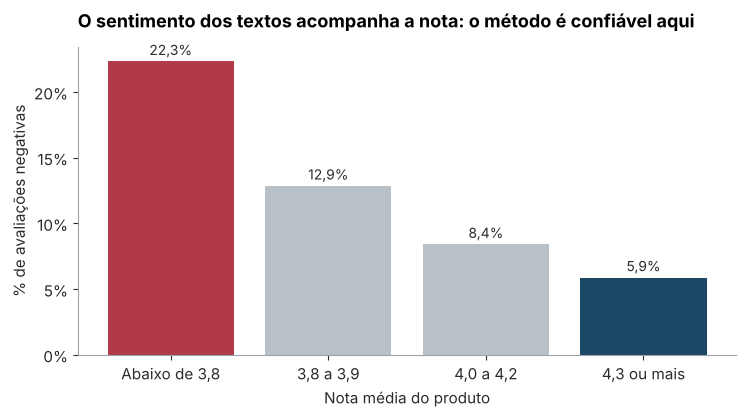

,% de avaliações negativas
Faixa de nota,
"Abaixo de 3,8","22,3"
"3,8 a 3,9","12,9"
"4,0 a 4,2","8,4"
"4,3 ou mais","5,9"


In [33]:
reviews['faixa_nota'] = pd.cut(reviews['rating'], [0, 3.79, 3.99, 4.29, 5],
                               labels=['Abaixo de 3,8', '3,8 a 3,9', '4,0 a 4,2', '4,3 ou mais'])
validacao = reviews.groupby('faixa_nota', observed=True)['negativa'].mean().mul(100)

fig, ax = plt.subplots(figsize=(8.5, 4))
ax.bar(validacao.index.astype(str), validacao.values, color=[VERMELHO, CINZA, CINZA, AZUL])
rotular_barras(ax, validacao.values, lambda v: fmt_pct(v))
eixo_percentual(ax)
ax.set_xlabel('Nota média do produto')
ax.set_ylabel('% de avaliações negativas')
ax.set_title('O sentimento dos textos acompanha a nota: o método é confiável aqui')
salvar(fig, '09_validacao_sentimento.png')
exibir(validacao.to_frame('% de avaliações negativas'))

**Observações:**
- 84% das avaliações são positivas e 10% são negativas, coerente com uma base em que a nota média é 4,09.
- O sentimento acompanha a nota: produtos abaixo de 3,8 têm 22% de avaliações negativas, contra 6% nos produtos com 4,3 ou mais. Essa validação nos dá segurança para usar o sentimento como medida de satisfação no nível do comentário.
- **Limitação:** o VADER não entende ironia nem frases com elogio e crítica juntos ("bom produto, mas parou de funcionar"). A validação manual abaixo mede o tamanho desse erro.

#### Validação manual

A comparação com a nota do produto mostra que o método acompanha a satisfação, mas não diz quantas vezes ele acerta. Para medir isso, lemos e rotulamos manualmente uma amostra de 100 avaliações: 50 que o VADER marcou como positivas, 30 como negativas e 20 como neutras. A amostra e os rótulos estão em `data/validacao/amostra_sentimento_rotulada.csv`.

In [34]:
amostra = pd.read_csv('../data/validacao/amostra_sentimento_rotulada.csv')
matriz = pd.crosstab(amostra['vader'], amostra['rotulo_manual'], margins=True, margins_name='Total')

acerto = amostra.assign(acerto=amostra['vader'] == amostra['rotulo_manual']).groupby('vader')['acerto'].mean()

# A amostra é estratificada: para os números gerais, cada classe pesa o quanto representa na base
peso = reviews['sentimento'].replace({'Neutra': 'Neutra ou mista'}).value_counts(normalize=True)
acerto_geral = (acerto * peso).sum() * 100
negativas_por_classe = amostra.groupby('vader')['rotulo_manual'].apply(lambda s: (s == 'Negativa').mean())
negativas_corrigida = (negativas_por_classe * peso).sum() * 100

print('Acerto por classe do VADER: ' + ' | '.join(f'{k}: {fmt_pct(v * 100, 0)}' for k, v in acerto.items()))
print(f'Acerto geral estimado (ponderado pela base): {fmt_pct(acerto_geral, 0)}')
print(f'% de avaliações negativas: {fmt_pct(reviews["negativa"].mean() * 100)} pelo VADER | '
      f'cerca de {fmt_pct(negativas_corrigida, 0)} corrigindo pela amostra')
exibir(matriz)

Acerto por classe do VADER: Negativa: 77% | Neutra ou mista: 30% | Positiva: 88%
Acerto geral estimado (ponderado pela base): 83%
% de avaliações negativas: 9,8% pelo VADER | cerca de 11% corrigindo pela amostra


Rótulo manual,Negativa,Neutra ou mista,Positiva,Total
Classificação do VADER,,,,
Negativa,23,4,3,30
Neutra ou mista,7,6,7,20
Positiva,1,5,44,50
Total,31,15,54,100


**Observações:**
- O VADER acerta 88% das avaliações que marca como positivas e 77% das que marca como negativas. Considerando o peso de cada classe na base, o acerto geral fica em torno de 83%.
- Os erros seguem um padrão: são avaliações mistas, que elogiam e criticam na mesma frase ("Product is very good, but delivery was not quite good").
- A classe neutra é a mais fraca (30% de acerto). Um terço dela é, na verdade, reclamação curta, como "Second quality" ou "Durability is an issue". Corrigindo pela amostra, a parcela real de avaliações negativas deve ficar perto de 11%, um pouco acima dos 9,8% medidos. Se há viés, portanto, é o de subestimar as reclamações, e as conclusões sobre os temas negativos são conservadoras.
- Usamos o VADER para comparar grupos (temas, categorias, faixas de desconto), e não para classificar avaliações uma a uma. Para esse uso, esse nível de acerto é suficiente.

<a id="secao-6-3"></a>

### 6.3 Temas das avaliações

Para saber *do que* os clientes falam, montamos um dicionário de temas com palavras e expressões em inglês. Ele foi construído lendo amostras de avaliações e as expressões de duas palavras mais frequentes (Seção 6.4), e não a partir de uma lista pronta. Uma avaliação pode ter mais de um tema.

In [35]:
temas = {
    'Custo-benefício': r'value for money|worth|price|budget|cheap|affordable|money',
    'Qualidade do produto': r'quality|build|material|sturdy|solid|premium|plastic',
    'Facilidade de uso': r'easy|simple|user friendly|handy|convenient',
    'Tamanho e encaixe': r'size|length|short|small|big|fit\b|fits|bulky|compact',
    'Bateria e carregamento': r'battery|charg|backup',
    'Design e aparência': r'design|look|color|colour|stylish|beautiful',
    'Desempenho e velocidade': r'speed|fast|slow|performance|lag',
    # 'broke/broken' só conta se não estiver falando de lacre, caixa ou embalagem (isso é entrega, não durabilidade)
    'Durabilidade e defeitos': (r'stopped working|not working|stop working|broken?(?!\s+(?:seal|box|packag))|defect|faulty|died|dead|'
                                r'durab|last(?:ed|s)? (?:only|for)|within (?:a |\d+ )?(?:days?|weeks?|months?)|'
                                r'after (?:a |\d+ |one |two |few )?(?:days?|weeks?|months?)'),
    'Som e áudio': r'sound|bass|audio|mic\b|volume|noise',
    'Conexão e compatibilidade': r'bluetooth|connect|pair|compatib|wifi|signal',
    'Entrega e embalagem': r'deliver|packag|packing|box\b|arrived|shipping',
    'Aquecimento e temperatura': r'heat|hot\b|warm|temperature',
    'Garantia e atendimento': r'warranty|customer (?:care|service|support)|service center|replace|refund|return',
    # revisado depois da validação manual (Seção 6.3): "picture" e "brightness" sozinhos geravam falsos positivos
    'Tela e imagem': r'(?<!product )\bdisplay\b|\bscreen\b|picture quality|resolution',
    'Instalação': r'install|setup|set up|technician|fitting',
}
texto_min = reviews['texto_completo'].str.lower()
for tema, padrao in temas.items():
    reviews[tema] = texto_min.str.contains(padrao, regex=True)

base_neg = reviews['negativa'].mean() * 100
tab_temas = pd.DataFrame({
    'avaliacoes': [reviews[t].sum() for t in temas],
    'pct_avaliacoes': [reviews[t].mean() * 100 for t in temas],
    'pct_positivas': [(reviews.loc[reviews[t], 'sentimento'] == 'Positiva').mean() * 100 for t in temas],
    'pct_negativas': [reviews.loc[reviews[t], 'negativa'].mean() * 100 for t in temas],
}, index=list(temas)).sort_values('avaliacoes', ascending=False)
tab_temas['vezes_a_media_negativa'] = tab_temas['pct_negativas'] / base_neg
print(f'% de avaliações negativas na base: {fmt_pct(base_neg)}')
print(f'Avaliações com ao menos um tema: {fmt_pct(reviews[list(temas)].any(axis=1).mean() * 100)}')
exibir(tab_temas, 1)

% de avaliações negativas na base: 9,8%
Avaliações com ao menos um tema: 67,4%


,Avaliações,% das avaliações,% positivas,% negativas,Vezes a média de negativas
Custo-benefício,1.679,"25,0","90,6","7,0","0,7"
Qualidade do produto,1.385,"20,6","86,7","10,6","1,1"
Facilidade de uso,763,"11,4","95,2","3,5","0,4"
Tamanho e encaixe,709,"10,6","87,3","8,2","0,8"
Bateria e carregamento,662,"9,9","79,5","13,7","1,4"
Design e aparência,606,"9,0","89,1","8,9","0,9"
Desempenho e velocidade,598,"8,9","83,4","10,0","1,0"
Durabilidade e defeitos,507,"7,5","65,5","27,4","2,8"
Som e áudio,452,"6,7","85,8","11,3","1,1"
Conexão e compatibilidade,399,"5,9","80,5","14,5","1,5"


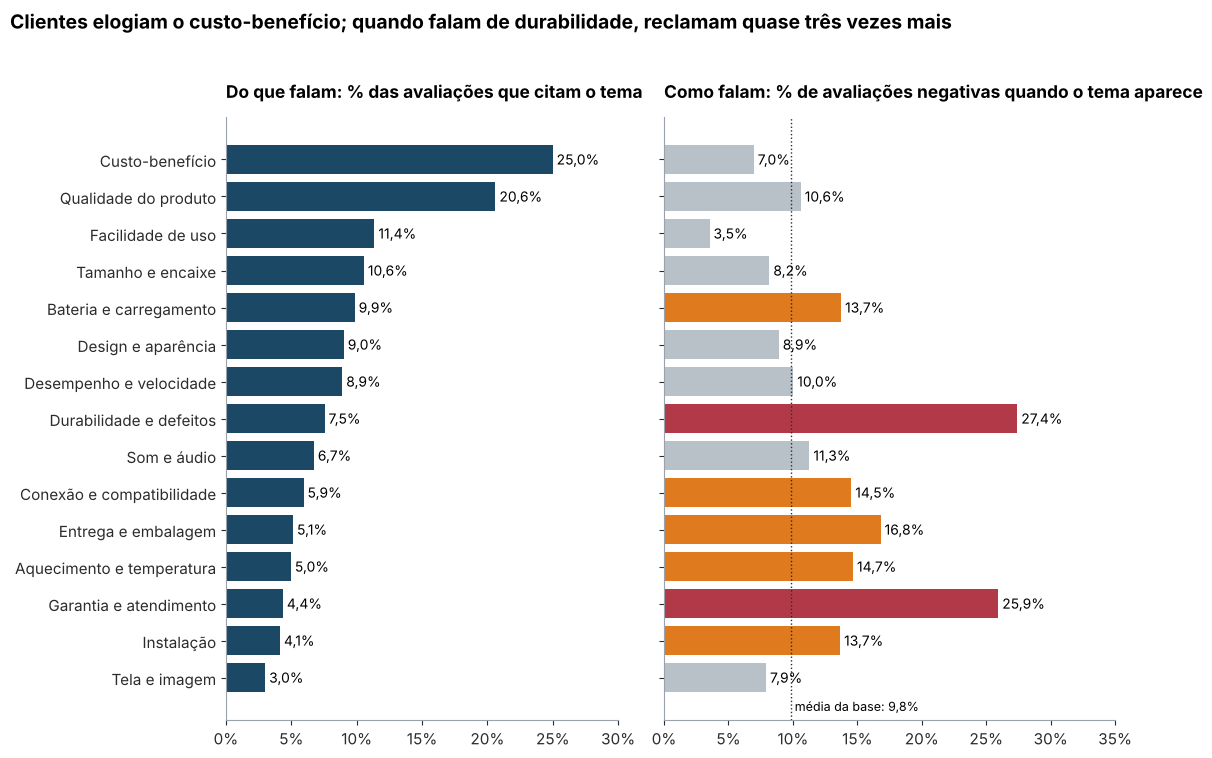

In [36]:
t = tab_temas.sort_values('pct_avaliacoes')
fig, axes = plt.subplots(1, 2, figsize=(11.5, 7.4), sharey=True, gridspec_kw={'width_ratios': [1, 1.15]})
for a in axes:
    a.tick_params(labelsize=11)

ax = axes[0]
ax.barh(t.index, t['pct_avaliacoes'], color=AZUL)
for i, v in enumerate(t['pct_avaliacoes']):
    ax.text(v + 0.3, i, fmt_pct(v), va='center', fontsize=10)
ax.set_xlim(0, 30)
eixo_percentual(ax, 'x')
ax.set_title('Do que falam: % das avaliações que citam o tema', fontsize=12.5)

ax = axes[1]
cores = [VERMELHO if v >= 2 * base_neg else (LARANJA if v > base_neg * 1.3 else CINZA) for v in t['pct_negativas']]
ax.barh(t.index, t['pct_negativas'], color=cores)
for i, v in enumerate(t['pct_negativas']):
    ax.text(v + 0.3, i, fmt_pct(v), va='center', fontsize=10)
ax.axvline(base_neg, color=TEXTO, linestyle=':', linewidth=1)
ax.text(base_neg + 0.3, -0.9, f'média da base: {fmt_pct(base_neg)}', fontsize=9)
ax.set_xlim(0, 35)
eixo_percentual(ax, 'x')
ax.set_title('Como falam: % de avaliações negativas quando o tema aparece', fontsize=12.5)

fig.suptitle('Clientes elogiam o custo-benefício; quando falam de durabilidade, reclamam quase três vezes mais',
             x=0.01, ha='left', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
salvar(fig, '10_temas_avaliacoes.png')

**Como ler este gráfico:** os dois painéis têm os mesmos temas, na mesma ordem. O da esquerda mostra a frequência; o da direita, quão negativo é o tom quando o tema aparece. A linha pontilhada é a média de avaliações negativas da base (10%). Em vermelho, temas com o dobro ou mais dessa média.

**Observações:**
- Custo-benefício é o assunto número um (25% das avaliações) e quase sempre aparece de forma positiva (91% positivas).
- Facilidade de uso é o tema mais positivo de todos (95%).
- Durabilidade e defeitos aparece em só 7,5% das avaliações, mas quando aparece é negativo em 27% dos casos, quase três vezes a média. Garantia e atendimento vem logo atrás (26%), e as duas coisas costumam vir juntas: o produto quebra e o cliente busca troca ou conserto.
- Entrega e embalagem é pouco citada (5%) e moderadamente negativa (17%). O problema principal está no produto, não na logística.

#### Os temas estão sendo bem identificados?

Também conferimos, uma a uma, avaliações marcadas em três temas: os dois que sustentam as conclusões (durabilidade e garantia) e o que nos pareceu mais sujeito a erro (tela e imagem). Para cada avaliação, verificamos se ela realmente fala do tema. A amostra está em `data/validacao/amostra_temas_rotulada.csv`.

In [37]:
amostra_temas = pd.read_csv('../data/validacao/amostra_temas_rotulada.csv')
precisao_temas = amostra_temas.groupby('tema')['tema_correto'].agg(acertos='sum', avaliacoes='size')
precisao_temas['precisão (%)'] = precisao_temas['acertos'] / precisao_temas['avaliacoes'] * 100

# "Tela e imagem" foi revisado depois desta conferência: medimos de novo só nas avaliações que o padrão novo ainda marca
tela = amostra_temas[amostra_temas['tema'] == 'Tela e imagem']
texto_tela = (tela['titulo'].fillna('') + ' ' + tela['texto'].fillna('')).str.lower()
tela_nova = tela[texto_tela.str.contains(temas['Tela e imagem'], regex=True)]
precisao_temas.loc['Tela e imagem (padrão revisado)'] = [tela_nova['tema_correto'].sum(), len(tela_nova),
                                                         tela_nova['tema_correto'].mean() * 100]
exibir(precisao_temas, 1)

,Acertos,Avaliações,precisão (%)
Tema,,,
Durabilidade e defeitos,31,40,"77,5"
Garantia e atendimento,15,20,"75,0"
Tela e imagem,11,20,"55,0"
Tela e imagem (padrão revisado),11,16,"68,8"


**Observações:**
- Durabilidade e defeitos: 78% de acerto. Os erros são menções a tempo que não falam de defeito, como "after 1 month you feel better sound". Como esses erros costumam ser avaliações neutras ou positivas, eles diluem a negatividade do tema: se os 27% de negativas estão errados, estão errados para baixo.
- Garantia e atendimento: 75%. Os erros vêm de palavras como "replacement" usadas em outro sentido ("comprei para substituir meu smartphone").
- Tela e imagem: 55% na primeira versão, porque o padrão pegava "picture" em "product pictures" e "brightness" de luminárias. Revisamos o padrão e a precisão subiu para 69%. É um tema secundário, que não sustenta nenhuma conclusão do trabalho.
- Um dicionário de palavras nunca será perfeito. Por isso a amostra rotulada fica no repositório: qualquer ajuste futuro no dicionário pode ser medido da mesma forma.

<a id="secao-6-4"></a>

### 6.4 Respondendo às perguntas do desafio

Para cada pergunta, olhamos as expressões de duas palavras mais frequentes em avaliações positivas e negativas e lemos exemplos reais.

In [38]:
from collections import Counter

stop = set('the a an and is it to of for in on with this that i my was are be as at but so have has its '
           "it's i'm am you your if can will one also all just from very good product nice".split())

def bigramas(serie, n=15):
    contagem = Counter()
    for texto in serie:
        palavras = [p for p in re.findall(r"[a-z']+", limpar(texto).lower()) if p not in stop]
        contagem.update(' '.join(par) for par in zip(palavras, palavras[1:]))
    return pd.DataFrame(contagem.most_common(n), columns=['expressão', 'avaliações'])

exibir(pd.concat({'Avaliações positivas': bigramas(reviews.loc[reviews['sentimento'] == 'Positiva', 'texto_completo']),
           'Avaliações negativas': bigramas(reviews.loc[reviews['negativa'], 'texto_completo'])}, axis=1))

In [39]:
def exemplos(filtro, n=4, seed=7):
    amostra = reviews[filtro & reviews['texto'].str.len().between(40, 170)].sample(n, random_state=seed)
    return exibir(amostra[['subcategoria', 'rating', 'titulo', 'texto']])

print('Negativas sobre o produto parar de funcionar:')
para_de_funcionar = reviews['texto_completo'].str.contains(r'stopped working|not working|after \w+ months?', case=False)
exemplos(reviews['negativa'] & para_de_funcionar)

Negativas sobre o produto parar de funcionar:


Subcategoria,Nota,Título,Texto
Acessórios e periféricos,"3,8","Worth for money, but for my case usb pin got broken after 1 month usage",go for it. use it carefully while plugging in
Impressoras e tintas,"3,6",After every 100 copy cartridge has to be replaced,"There is some serious issue with the product, it is not working now, need service engineer to repair it."
Eletroportáteis,"3,3",Product is not working smoothly...after very hard press the button then it works.,Product is not working smoothly...after very hard press the button then it works.
Material elétrico,"4,0",Adapter,my adapter fallen from charging point its not working


In [40]:
print('Positivas que falam de custo-benefício:')
exemplos((reviews['sentimento'] == 'Positiva') & reviews['Custo-benefício'])

Positivas que falam de custo-benefício:


Subcategoria,Nota,Título,Texto
Eletrônicos de escritório,"4,4",Good product with reasonable price,I Like this product. The product is genuine onky
"TV, vídeo e home theater","3,4",Acceptable for the price,"It is acceptable for the price ( INR 399 ) , works as intended , however buttons require additional force as it's hard."
"Aquecimento, ventilação e ar","4,1",Good Product,It is very good product at this price and I am very impressed with it easy to use and anyone can easily use it so you can buy it
Acessórios e periféricos,"4,3",Value for money product.,Liked the length of the wire. The quality is good. Does it's job.


**1. O que os clientes mais valorizam?**
Custo-benefício e facilidade de uso. "Value for money", "easy to use", "worth (the) money" e "price range" lideram as expressões das avaliações positivas. O cliente desta base compra pensando no preço e fica satisfeito quando o produto entrega o básico sem complicação.

**2. Quais problemas aparecem com maior frequência?**
O produto parar de funcionar pouco tempo depois da compra. "Not working", "stopped working", "working after" e "after (x) months" estão entre as expressões mais comuns das avaliações negativas, junto com "poor quality" e "waste (of) money". Em seguida vem garantia e atendimento, o segundo tema mais negativo da Seção 6.3: depois do defeito, o cliente tenta a troca ou o conserto e também se frustra.

**3. Quais padrões estão presentes em avaliações positivas?**
São curtas, falam de preço e da experiência inicial ("works well", "easy to use", "build quality"). Em eletrônicos, aparecem atributos concretos: "fast charging", "sound quality", "battery life".

**4. Quais temas aparecem em avaliações negativas?**
Durabilidade, qualidade abaixo do esperado e atendimento pós-venda. É comum a avaliação negativa começar com um elogio ("good product at this price") e terminar com o defeito. Isso é sinal de que o problema aparece **depois** da primeira impressão, quando a nota já pode ter sido dada.

<a id="secao-6-5"></a>

### 6.5 Onde os comentários complementam a nota

Aqui está o ponto em que a análise de texto complementa os indicadores. Fizemos três cruzamentos.

**a) Onde a durabilidade preocupa mais**

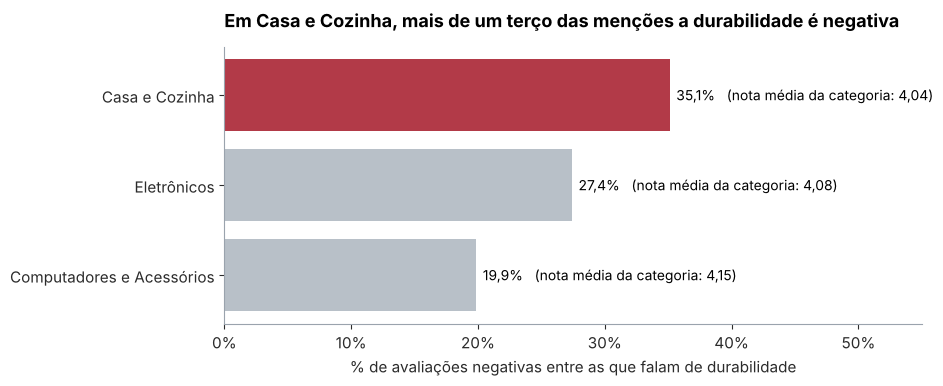

,Avaliações,% negativas
Categoria,,
Computadores e Acessórios,171,"19,9"
Eletrônicos,175,"27,4"
Casa e Cozinha,148,"35,1"


In [41]:
dur = (reviews[reviews['Durabilidade e defeitos']].groupby('categoria')
       .agg(avaliacoes=('review_id', 'size'), pct_negativas=('negativa', 'mean')))
dur['pct_negativas'] *= 100
dur = dur[dur['avaliacoes'] >= 30].sort_values('pct_negativas')
nota_cat = validos.groupby('categoria')['rating'].mean()

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.barh(dur.index, dur['pct_negativas'], color=[CINZA, CINZA, VERMELHO])
for i, (c, v) in enumerate(dur['pct_negativas'].items()):
    ax.text(v + 0.5, i, f'{fmt_pct(v)}   (nota média da categoria: {fmt_num(nota_cat[c], 2)})', va='center', fontsize=10)
ax.set_xlim(0, 55)
eixo_percentual(ax, 'x')
ax.set_xlabel('% de avaliações negativas entre as que falam de durabilidade')
ax.set_title('Em Casa e Cozinha, mais de um terço das menções a durabilidade é negativa')
salvar(fig, '11_durabilidade_por_categoria.png')
exibir(dur, 1)

**Observações:**
- Em Casa e Cozinha, 35% das avaliações que falam de durabilidade são negativas, contra 20% em Computadores e Acessórios. É um padrão que a nota média não mostra: as três categorias têm notas entre 4,04 e 4,15.
- Faz sentido pelo tipo de produto: eletroportáteis e aquecedores são itens que o cliente espera usar por anos, e uma falha em poucos meses pesa mais.

**b) Desconto agressivo e reclamação de durabilidade**

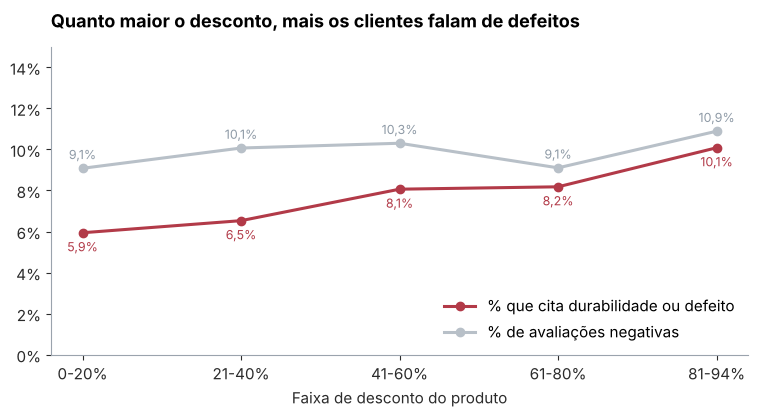

,% cita durabilidade ou defeito,% negativas,% cita custo-benefício
Faixa de desconto,,,
0-20%,"5,9","9,1","18,9"
21-40%,"6,5","10,1","23,7"
41-60%,"8,1","10,3","26,5"
61-80%,"8,2","9,1","26,8"
81-94%,"10,1","10,9","27,8"


In [42]:
por_desc = reviews.groupby('faixa_desconto', observed=True).agg(
    pct_cita_durabilidade=('Durabilidade e defeitos', 'mean'),
    pct_negativas=('negativa', 'mean'),
    pct_cita_preco=('Custo-benefício', 'mean'),
).mul(100)

fig, ax = plt.subplots(figsize=(9, 4))
x = por_desc.index.astype(str)
ax.plot(x, por_desc['pct_cita_durabilidade'], marker='o', color=VERMELHO, linewidth=2.2,
        label='% que cita durabilidade ou defeito')
ax.plot(x, por_desc['pct_negativas'], marker='o', color=CINZA, linewidth=2.2, label='% de avaliações negativas')
for serie, cor, desloc in [('pct_cita_durabilidade', VERMELHO, -0.9), ('pct_negativas', '#8E9AA6', 0.45)]:
    for xi, v in zip(x, por_desc[serie]):
        ax.text(xi, v + desloc, fmt_pct(v), ha='center', fontsize=9, color=cor)
ax.set_ylim(0, 15)
eixo_percentual(ax)
ax.set_xlabel('Faixa de desconto do produto')
ax.set_title('Quanto maior o desconto, mais os clientes falam de defeitos')
ax.legend(frameon=False, loc='lower right')
salvar(fig, '12_desconto_vs_durabilidade.png')
exibir(por_desc, 1)

**Observações:**
- A menção a durabilidade e defeitos cresce de 5,9% nos produtos com até 20% de desconto para 10,1% nos com mais de 80%, um aumento de cerca de 70%.
- Esse é o elo que faltava na Seção 5.2. Os números mostravam que produtos com desconto agressivo têm nota menor; os comentários mostram o motivo mais provável: o cliente percebe qualidade e durabilidade inferiores.

**c) Produtos com boa nota e comentários preocupantes**

Procuramos produtos com nota ≥ 4,0 em que **3 ou mais das avaliações exibidas são negativas**. Usamos 3 como mínimo porque, com até 8 avaliações por produto, 1 ou 2 negativas podem ser acaso.

In [43]:
por_familia = reviews.groupby('familia_id').agg(
    avaliacoes=('review_id', 'size'),
    negativas=('negativa', 'sum'),
    durabilidade_negativa=('Durabilidade e defeitos', lambda s: (s & reviews.loc[s.index, 'negativa']).sum()),
)
info = df.drop_duplicates('familia_id').set_index('familia_id')[['nome_curto', 'categoria', 'subcategoria',
                                                                  'rating', 'rating_count']]
por_familia = por_familia.join(info)
alerta = (por_familia[(por_familia['rating'] >= 4.0) & (por_familia['negativas'] >= 3)]
          .sort_values(['negativas', 'rating_count'], ascending=False))
print(f'Famílias com nota ≥ 4,0 e 3 ou mais avaliações negativas: {len(alerta)} '
      f'de {(por_familia["rating"] >= 4.0).sum()} bem avaliadas')
print('Por categoria:', alerta['categoria'].value_counts().to_dict())
exibir(alerta[['nome_curto', 'subcategoria', 'rating', 'rating_count', 'avaliacoes', 'negativas']].head(10).rename(columns={'avaliacoes': 'Avaliações de texto'}))

Famílias com nota ≥ 4,0 e 3 ou mais avaliações negativas: 14 de 632 bem avaliadas
Por categoria: {'Casa e Cozinha': 6, 'Computadores e Acessórios': 3, 'Eletrônicos': 3, 'Escritório': 1, 'Outras': 1}


,Produto,Subcategoria,Nota,Avaliações,Avaliações de texto,Negativas
Família,,,,,,
641,Philips EasyTouch Plus Standing Garment Steamer GC523/60 - 1,Eletroportáteis,"4,0",3.160,8,4
657,Morphy Richards OFR Room Heater,"Aquecimento, ventilação e ar","4,0",2.961,8,4
91,Bajaj Rex 500W Mixer Grinder with Nutri-Pro Feature,Eletroportáteis,"4,2",41.349,8,3
147,Zebronics Zeb-Transformer Gaming Keyboard and Mouse Combo,Acessórios e periféricos,"4,3",27.223,8,3
185,D-Link DIR-615 Wi-fi Ethernet-N300 Single_band 300Mbps Route,"Redes (roteadores, adaptadores)","4,1",22.375,8,3
345,HUL Pureit Germkill kit for Classic 23 L water purifier - 15,Eletroportáteis,"4,1",10.907,8,3
594,Luxor 5 Subject Single Ruled Notebook - A4,Papelaria,"4,5",3.785,8,3
642,Ambrane 27000mAh Power Bank,Celulares e acessórios,"4,1",3.156,8,3
694,ESnipe Mart Worldwide Travel Adapter with Build in Dual USB,Material elétrico,"4,0",2.581,8,3


**Observações:**
- Encontramos 14 produtos bem avaliados com sinais de problema nos comentários, quase metade deles em Casa e Cozinha. Olhando só a nota, eles não chamariam atenção.
- Essa lista só aparece com a análise de texto e funciona como alerta antecipado: são produtos que podem começar a perder nota.

<a id="secao-6-6"></a>

### 6.6 O que as descrições prometem × o que os clientes percebem

O desafio também pede a análise das descrições dos produtos (`about_product`). Testamos uma pergunta simples: **quando a descrição promete algo, os clientes confirmam?** Escolhemos duas promessas frequentes e verificáveis nos comentários.

In [44]:
descricao = df.set_index('product_id')['about_product'].str.lower()
promessas = {
    'Carregamento rápido': (r'fast charg|quick charg|rapid charg', 'Bateria e carregamento'),
    'Durabilidade': (r'durab|long.lasting|sturdy|robust|heavy.duty|tough', 'Durabilidade e defeitos'),
}
resultado = []
for promessa, (padrao, tema) in promessas.items():
    promete = reviews['product_id'].map(descricao.str.contains(padrao)).fillna(False)
    for flag, grupo in [(True, 'Promete'), (False, 'Não promete')]:
        s = reviews[promete == flag]
        resultado.append({'promessa': promessa, 'grupo': grupo, 'avaliacoes': len(s),
                          'pct_cita_tema': s[tema].mean() * 100,
                          'pct_negativas_quando_cita': s.loc[s[tema], 'negativa'].mean() * 100,
                          'pct_reclama_do_tema': (s[tema] & s['negativa']).mean() * 100})
exibir(pd.DataFrame(resultado).set_index(['promessa', 'grupo']), 1)

**Como ler esta tabela:** "% cita o tema" é a parcela de avaliações que fala do assunto prometido; "% negativas quando cita" mostra o tom quando fala; e "% reclama do tema" é a parcela de todas as avaliações que reclama daquele assunto.

**Observações:**
- Carregamento rápido é uma promessa cumprida. Nos produtos que a anunciam, 39% das avaliações falam de bateria ou carregamento (contra 7% nos demais), e o tom é mais positivo (11% negativas, contra 15%). A promessa vira assunto e o cliente confirma. Como se fala muito mais do tema, o volume de reclamações sobre carregamento também é maior (4,3% das avaliações, contra 1,1%). O ponto é que, proporcionalmente, a experiência é melhor.
- Com durabilidade, o resultado é mais modesto. Os produtos que se dizem duráveis são um pouco mais comentados nesse aspecto e com tom menos negativo, mas a parcela de avaliações que reclama de defeito fica praticamente igual à dos outros produtos (veja a última coluna).
- Esperávamos o contrário: que promessa não cumprida gerasse mais reclamação. Essa hipótese não se confirmou. Nas duas promessas testadas, o que a descrição anuncia vira assunto nas avaliações e, em geral, é confirmado.

<a id="secao-7"></a>

## 7. Exportação das Bases para o Power BI

O tratamento da base de produtos será refeito no Power Query, a partir do `amazon.csv` bruto. Exportamos aqui:
- `produtos_tratados.csv`: a base tratada, usada para conferir se os números do Power BI batem com os do notebook;
- `reviews_sentimento.csv`: uma linha por avaliação, com sentimento e temas. É a parte que o Power BI não faz sozinho e que entra no modelo;
- `reviews_temas.csv`: a mesma informação em formato longo (uma linha por avaliação e tema), mais prática para os visuais.

In [45]:
import os
os.makedirs('../data/processed', exist_ok=True)

colunas_produto = ['product_id', 'nome_curto', 'product_name', 'categoria', 'subcategoria', 'categoria_final',
                   'actual_price', 'discounted_price', 'discount_percentage', 'economia', 'rating', 'rating_count',
                   'nota_ponderada', 'faixa_desconto', 'faixa_preco', 'faixa_nota', 'quadrante', 'familia_id']
df[colunas_produto].to_csv('../data/processed/produtos_tratados.csv', index=False, encoding='utf-8')

colunas_review = ['review_id', 'product_id', 'familia_id', 'titulo', 'texto', 'score_sentimento', 'sentimento'] + list(temas)
reviews[colunas_review].to_csv('../data/processed/reviews_sentimento.csv', index=False, encoding='utf-8')

temas_longo = (reviews.melt(id_vars=['review_id', 'product_id', 'familia_id', 'sentimento'], value_vars=list(temas),
                            var_name='tema', value_name='cita')
               .query('cita').drop(columns='cita'))
temas_longo.to_csv('../data/processed/reviews_temas.csv', index=False, encoding='utf-8')

for arq, base in [('produtos_tratados', df), ('reviews_sentimento', reviews), ('reviews_temas', temas_longo)]:
    print(f'{arq}.csv: {fmt_num(len(base))} linhas')

produtos_tratados.csv: 1.351 linhas
reviews_sentimento.csv: 6.718 linhas
reviews_temas.csv: 9.212 linhas


<a id="secao-7-1"></a>

### 7.1 Números oficiais do projeto

Estes são os valores que vão para o dashboard, o relatório, o README e o vídeo. Qualquer número citado em outro arquivo precisa sair desta tabela.

In [46]:
oficiais = pd.Series({
    'Produtos analisados': fmt_num(len(df)),
    'Produtos com nota válida': fmt_num(len(validos)),
    'Nota média': fmt_num(validos['rating'].mean(), 2),
    '% de produtos com nota ≥ 4,0': fmt_pct((validos['rating'] >= 4).mean() * 100),
    'Avaliações (por família de variantes)': fmt_num(familias['avaliacoes'].sum()),
    'Avaliações por produto (mediana)': fmt_num(validos['rating_count'].median()),
    'Desconto médio': fmt_pct(validos['discount_percentage'].mean()),
    'Preço final mediano': '₹' + fmt_num(validos['discounted_price'].median()),
    'Economia média por produto': '₹' + fmt_num(validos['economia'].mean()),
    'Top 10% dos produtos: % das avaliações': fmt_pct(top10),
    'Avaliações de texto analisadas': fmt_num(len(reviews)),
    '% de avaliações positivas': fmt_pct((reviews['sentimento'] == 'Positiva').mean() * 100),
    '% de avaliações negativas': fmt_pct(reviews['negativa'].mean() * 100),
}, name='valor')
exibir(oficiais.to_frame())

,Valor
Produtos analisados,1.351
Produtos com nota válida,1.350
Nota média,"4,09"
"% de produtos com nota ≥ 4,0","74,8%"
Avaliações (por família de variantes),16.796.897
Avaliações por produto (mediana),4.740
Desconto médio,"46,7%"
Preço final mediano,₹896
Economia média por produto,₹2.388
Top 10% dos produtos: % das avaliações,"60,0%"


<a id="secao-8"></a>

## 8. Conclusão e Recomendações

**O que encontramos**

- Desconto agressivo não é uma boa estratégia nesta base. Produtos com mais de 80% de desconto têm muito menos chance de serem bem avaliados (57% com nota ≥ 4,0, contra 83% dos que descontam até 20%) e não recebem mais avaliações. O efeito se mantém mesmo controlando preço e categoria (a chance de nota ≥ 4,0 cai cerca de 13% a cada 10 pontos de desconto) e é mais forte nos produtos baratos. Os comentários sugerem o motivo: quanto maior o desconto, mais os clientes falam de defeitos.
- A reputação da loja depende de poucos produtos. 10% dos produtos concentram cerca de 60% das avaliações. Entre os muito avaliados, 40 famílias têm nota abaixo de 4,0, principalmente fones de ouvido e eletroportáteis.
- Casa e Cozinha é a categoria com mais oportunidade e mais risco ao mesmo tempo. Tem um terço do portfólio e só 18% das avaliações, é onde o desconto alto mais se associa a nota baixa e, nos comentários, tem a maior taxa de reclamação sobre durabilidade (35%).
- O cliente valoriza custo-benefício e facilidade de uso, e reclama de durabilidade e pós-venda. Durabilidade aparece em poucas avaliações, mas é negativa quase três vezes mais que a média. A logística não é o problema principal.
- **Os comentários mostram problemas antes da nota:** 14 produtos com nota ≥ 4,0 já mostram 3 ou mais avaliações negativas.

**Alcance de cada recomendação**

Sem dados de vendas, medimos o tamanho de cada recomendação pelo número de avaliações dos produtos envolvidos, contando cada família de variantes uma vez. É uma forma de saber quantos clientes cada ação atinge.

In [47]:
total_aval = familias['avaliacoes'].sum()

def alcance(mascara):
    fams = df.loc[mascara, 'familia_id'].unique()
    aval = familias.loc[fams, 'avaliacoes'].sum()
    return pd.Series({'produtos': int(mascara.sum()), 'famílias': len(fams),
                      'avaliações': aval, '% das avaliações': aval / total_aval * 100})

nota, aval = df['rating'], df['rating_count']
promete_carga = df['product_id'].map(descricao.str.contains(promessas['Carregamento rápido'][0])).fillna(False).astype(bool)
negativas_produto = df['product_id'].map(reviews.groupby('product_id')['negativa'].sum()).fillna(0)

alcance_rec = pd.DataFrame({
    '1. Desconto acima de 60%': alcance((df['discount_percentage'] > 60) & nota.notna()),
    '1a. ... só itens até ₹200': alcance((df['discount_percentage'] > 60) & nota.notna() & (df['discounted_price'] <= 200)),
    '2. Risco de reputação': alcance((aval >= p75) & (nota < 4)),
    '3. Oportunidade de visibilidade': alcance(aval.between(100, p25) & (nota >= 4.3)),
    '4. Eletroportáteis e aquecimento': alcance(df['subcategoria'].isin(['Eletroportáteis', 'Aquecimento, ventilação e ar'])),
    '5. Alerta nos comentários': alcance((nota >= 4) & (negativas_produto >= 3)),
    '6. Prometem carregamento rápido': alcance(promete_carga),
}).T
exibir(alcance_rec, 1)

,Produtos,famílias,avaliações,% das avaliações
1. Desconto acima de 60%,377,322,5.443.336,"32,4"
1a. ... só itens até ₹200,83,70,551.175,"3,3"
2. Risco de reputação,49,40,1.932.843,"11,5"
3. Oportunidade de visibilidade,60,58,28.810,"0,2"
4. Eletroportáteis e aquecimento,424,424,2.603.527,"15,5"
5. Alerta nos comentários,14,14,122.570,"0,7"
6. Prometem carregamento rápido,154,105,1.379.744,"8,2"


**Recomendações**

| Achado | Ação | Onde | Alcance | Como acompanhar |
|---|---|---|---|---|
| Desconto alto reduz a chance de nota ≥ 4,0 (−13% a cada 10 pontos, mesmo controlando preço e categoria) e não traz mais engajamento | Revisar a política de descontos: acima de 60%, só para produtos com nota ≥ 4,0 | Começar pelos 83 itens de até ₹200 com mais de 60% de desconto, a maioria cabos e acessórios | 377 produtos com desconto acima de 60%, que somam 32% das avaliações | % de produtos com nota ≥ 4,0 na faixa acima de 60% |
| 40 famílias muito avaliadas com nota abaixo de 4,0 | Plano de qualidade com os fornecedores ou substituição dos itens | Fones de ouvido e eletroportáteis | 1,93 milhão de avaliações (11,5% do total) | Nota e % de avaliações negativas desses produtos |
| 58 produtos bem avaliados e pouco vistos | Dar exposição: destaque na busca, recomendação e campanhas | Lista da Seção 5.3, começando por Casa e Cozinha | Hoje somam só 0,2% das avaliações: quase todo o ganho está por vir | Avaliações recebidas por esses produtos |
| Durabilidade é o principal motivo de reclamação | Exigir garantia mínima dos fornecedores e monitorar devoluções por defeito | Eletroportáteis e aquecimento (Casa e Cozinha) | 424 produtos, 15,5% das avaliações | % de avaliações que citam defeito |
| 14 produtos com boa nota e comentários negativos | Monitoramento de texto como alerta antecipado | Lista da Seção 6.5 | 122,6 mil avaliações (0,7%) | Nº de avaliações negativas por produto |
| O que a descrição promete vira assunto e é confirmado | Destacar nas descrições os atributos que os clientes mais elogiam em cada subcategoria | Todo o catálogo | 154 produtos já prometem carregamento rápido (8,2% das avaliações) | Menções positivas aos atributos destacados |

**Limitações**
- A base não tem vendas nem receita. Usamos o número de avaliações como proxy de popularidade.
- Os preços estão em rúpias indianas e refletem o mercado da Amazon Índia.
- A base traz até 8 avaliações por produto, que são as exibidas na página e não o histórico completo. O sentimento foi calculado sobre o texto, porque não existe nota por avaliação.
- Na validação manual, o sentimento acertou cerca de 83% das avaliações e tende a subestimar as negativas; os temas principais acertaram de 75% a 78%.
- As relações encontradas são associações, não causa e efeito. Confirmar o efeito do desconto exigiria um teste controlado.

**Próximos passos**
- Cruzar estes resultados com dados de vendas e devoluções, se a empresa tiver.
- Testar um modelo de tópicos (por exemplo, BERTopic) para descobrir temas que o dicionário não cobre.
- Acompanhar a lista de alertas ao longo do tempo para validar se esses produtos realmente perdem nota.